# Predicting *Avatar: Fire and Ash* First-Week Domestic Box Office

## 1. Project Overview & Objective

**Business Context**
The *Avatar* franchise represents a unique statistical anomaly in the film industry, historically outperforming standard market models by significant margins. Predicting the performance of the upcoming movie, *Avatar: Fire and Ash* (late 2025), requires more than standard regression. It demands a system capable of adapting to the post-pandemic "New Normal" of theatrical exhibition while accounting for the specific "blockbuster bias" associated with James Cameron's films.

**Modeling Objective**
The goal is to build a robust, time-aware machine learning pipeline to forecast the **First-Week Domestic Box Office Gross (USD)**. Unlike standard analysis, this project treats box office prediction as a **Time-Series** problem, prioritizing recent market dynamics over historical averages to ensure the model is calibrated for the 2025 landscape.

**The "New Normal" Challenge**
The cinema industry underwent a structural shift (post-COVID recovery and the rise of streaming). A model trained equally on 2010 and 2024 data risks obsolescence. This project addresses this through:
1.  **Exponential Time Decay:** Applying a 6-year half-life to training data to prioritize recent trends.
2.  **Era-Weighted Validation:** Explicitly optimizing for performance on the post-2023 "New Normal" era (60% weight) vs. historical stability (40% weight).
3.  **Uplift Calibration:** Using *Avatar: The Way of Water* as a benchmark to calculate and apply a "Cameron Factor" adjustment to the final prediction.

**Target Variable**
* `revenue_first_week_raw_movie`: Modeled in **Log-Space (`log1p`)** to normalize the heavy right-tail distribution of financial data, then converted back to real dollars for final reporting.

**Key Feature Groups**
* **Movie Related Features:** Budget, theater count, runtime, production country, and language etc.
* **Director Features:** Years in the feild, prior movies count, prior average budget etc.
* **Franchise Features:** Franchise flag, prior films budget and revenue related features.
* **Cast Features:** Co-star affinity, genre match, director collaboration, and prior average budget features accounting for 'star-power'.
* **Production Company Features:** Production companies past movies count, budget, direction collaboration features.

**Model Strategy**
* **Algorithm:** 11 different algorithms are tested on 2 horizons leading to a data driven decision to use **Explainable Boosting Machine (EBM)**. Ensemble of multiple models also tested with a **Caruana Hill Climbing Ensemble** of tree-based models, but was beat by EBM.
* **Evaluation:** performance is measured using mainly **RMSE (Root Mean Squared Error)**, supplemented by **MAE (Mean Absolute Error)** on a strictly held-out test set to simulate the *Avatar 3* release environment.

# 2. Imports & Global Configuration

This section establishes the technical foundation for the entire project. Before diving into analysis or modeling, this section ensures environment is properly set up to ensure the code runs smoothly and the results are reliable.

* **2.1 Library Imports:** The process begins by bringing in the necessary software tools. This includes libraries for data manipulation (like Pandas), visualization tools for creating charts, and the machine learning algorithms that will power the prediction models.

* **2.2 Global Configuration:** To ensure scientific rigor, specific "ground rules" are set here. A random seed is applied to control randomness, guaranteeing that the analysis produces the exact same results every time it runs (reproducibility).

* **2.3 Data Paths:** This block defines exactly where the project files are located. It creates a flexible system to find the data, regardless of where the code is run.

* **2.4 Initial Data Load:** Finally, the raw dataset is loaded into memory. An immediate "health check" is performed to look for missing values, duplicates, or weird anomalies before any complex processing begins.

In [ ]:
2.1 # Imports & Global Configuration

# --- Standard library ---
import os
import sys
import random
import logging
from pathlib import Path
from typing import Tuple, List
import warnings
warnings.filterwarnings("ignore")

# --- Third-party libraries ---
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
from interpret.glassbox import ExplainableBoostingRegressor

from scipy import stats

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import xgboost as xgb
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from tabpfn import TabPFNRegressor
import optuna
import shap
import scipy.stats as stats

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from interpret.glassbox import ExplainableBoostingRegressor

# Boosting libs
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

# Optional EBM
EBM_AVAILABLE = False
try:
    from interpret.glassbox import ExplainableBoostingRegressor
    EBM_AVAILABLE = True
except Exception:
    EBM_AVAILABLE = False

# TabPFN
TABPFN_AVAILABLE = False
try:
    from tabpfn import TabPFNRegressor
    TABPFN_AVAILABLE = True
except Exception:
    TABPFN_AVAILABLE = False


In [ ]:
# 2.2 --- Global config ---
GLOBAL_SEED = 42

# Set global seed for reproducibility
def set_global_seed(seed: int = GLOBAL_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_global_seed()

# Pandas display options
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

# Matplotlib / Seaborn defaults
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Logging setup
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
)
logger = logging.getLogger("avatar3_boxoffice")

# Basic environment log
logger.info("Python version: %s", sys.version.split()[0])
logger.info("Pandas version: %s", pd.__version__)
logger.info("NumPy version: %s", np.__version__)
logger.info("Seaborn version: %s", sns.__version__)
logger.info("Optuna version: %s", optuna.__version__)
logger.info("SHAP version: %s", shap.__version__)

In [431]:
# 2.3 Data Paths & Dataset Loader
from pathlib import Path

# Define PROJECT_ROOT as the current working directory
PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT 
RAW_DATA_PATH = DATA_DIR / "avatar_prediction_dataset.csv"

# Load raw dataset and check for basic issues
def load_raw_dataset(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Data file not found: {path}")

    logger.info("Loading raw dataset from %s", path)
    df = pd.read_csv(path)

    logger.info("Loaded %d rows and %d columns", df.shape[0], df.shape[1])

    # Simple duplicate check (row-wise)
    dup_count = df.duplicated().sum()
    if dup_count > 0:
        logger.warning("Detected %d fully duplicated rows in the raw dataset", dup_count)

    return df


In [ ]:
# 2.4 Initial Data Load & Quick Sanity Checks
 
raw_df = load_raw_dataset(RAW_DATA_PATH)
logger.info("First 5 rows of the raw dataset:")
display(raw_df.head())

logger.info("Basic DataFrame info:")
raw_df.info()

# Quick missing-value overview (fraction of missing per column)
na_fraction = raw_df.isna().mean().sort_values(ascending=False)
logger.info("Top 10 columns by missing fraction:")
display(na_fraction.head(10))

# Basic numeric summary for key money/theater features if present
key_numeric_cols = [
    "revenue_first_week_adjusted_movie",
    "budget_adjusted_movie",
    "revenue_first_week_raw_movie",
    "budget_raw_movie"
    "opening_theater_count_movie",
    "runtime_minutes_movie",
]

existing_numeric_cols = [c for c in key_numeric_cols if c in raw_df.columns]

if existing_numeric_cols:
    logger.info("Summary stats for key numeric columns:")
    display(raw_df[existing_numeric_cols].describe().T)
else:
    logger.warning("None of the expected key numeric columns were found in the dataset.")


# 3. Data Cleaning, Filtering & Schema Validation

Raw data is rarely ready for immediate analysis. This section systematically refines the dataset to ensure high quality and consistency.

* **3.1 Column Type Conversion:** First, the code enforces correct data types. Numerical columns (like average runtime or year counts) are explicitly cast to floats, and dates are converted to datetime objects. This prevents errors where numbers might be read as text.

* **3.2 Flexible Filtering:** To focus the analysis on relevant commercial films, the data is filtered. Movies with extremely low budgets or revenues (likely errors or amateur productions) are removed. This step ensures the model trains on viable theatrical releases rather than outliers.

* **3.3 Schema Definition & Validation:** This is a rigorous quality control step. Instead of manually checking every row, the code defines a "Schema"—a set of strict rules (e.g., "Budget must be greater than 0") and also a check on some features (e.g. "How many movies have theaters between 600 and 5,000"). A validation function then scans the dataset against these rules, automatically flagging any data points that violate logical boundaries.

* **3.4 Missing Value Check:** After filtering and validation, a final scan identifies remaining missing values. This highlights which columns will need imputation (filling in blanks) in later steps.

* **3.5 Target Selection:** Finally, the dataset supports both **First Week Revenue** and **Opening Weekend Revenue** prediction. Here, the primary goal is to predict the **First Week Revenue**, the "Opening Weekend" column is dropped to prevent leakage and redundancy. Also this model uses raw values for the target feature and the budget, that's why the adjusted versions are dropped. However, the "Star Power" proxy monetary values (avg cast budget, avg director budget) are kept adjusted to ensure they caputre historical star power in current monetary terms.

In [433]:
# 3.1 Convert columns to required types

# Convert columns to float
float_cols = [
    "prod_avg_movies_per_year_prod",
    "avg_genre_fit_cast",
    "avg_films_with_director_cast",
    "avg_costar_affinity_cast",
    "avg_runtime_L10_director",
    "years_since_last_film_director",
    "years_active_director",
    "years_since_last_franchise_film_franchise"
]
for col in float_cols:
    if col in raw_df.columns:
        raw_df[col] = raw_df[col].astype(float)
    else:
        logger.warning(f"Column '{col}' not found for float conversion.")

# Convert column to datetime
datetime_col = "release_date_movie"
if datetime_col in raw_df.columns:
    raw_df[datetime_col] = pd.to_datetime(raw_df[datetime_col], errors="coerce")
else:
    logger.warning(f"Column '{datetime_col}' not found for datetime conversion.")

In [ ]:
# 3.2 Flexible filtering with easy toggling

df_filtered = raw_df.copy()

# Filters to apply
filters = [
    #(df_filtered["opening_theater_count_movie"] >= 600), 
    (df_filtered["budget_adjusted_movie"] > 10_000),
    (df_filtered["revenue_first_week_adjusted_movie"] > 10_000),
    (df_filtered["total_cast_size_cast"] > 0),
    # (df_filtered["runtime_minutes_movie"] >= 90),      
    # (df_filtered["is_franchise_franchise"] == True),
]

# Combine all active filters
if filters:
    combined_filter = filters[0]
    for f in filters[1:]:
        combined_filter &= f
    df_filtered = df_filtered[combined_filter]

print(f"Filtered dataset length: {len(df_filtered)}")
print(f"Filtered dataset shape: {df_filtered.shape}")

In [ ]:
# 3.3 Schema definition & validation helpers

from pandas.api.types import (
    is_numeric_dtype,
    is_bool_dtype,
    is_datetime64_any_dtype,
)

# Expected schema for the current dataset.
SCHEMA_EXPECTATIONS = {
    # --- Target ---
    "revenue_first_week_raw_movie": {
        "required": True,
        "kind": "numeric",    
        "min": 10_000,      # check values below a threshold
        "max": 500_000_000,  # sanity upper bound
        "allow_missing": False,
    },

    # --- Core numeric drivers ---
    "budget_raw_movie": {
        "required": True,
        "kind": "numeric",
        "min": 100_000,
        "max": 500_000_000,
        "allow_missing": False,
    },
    "opening_theater_count_movie": {
        "required": True,
        "kind": "numeric",
        "min": 600,
        "max": 5_000,  # sanity bound for US theater count
        "allow_missing": False,
    },
    "total_cast_size_cast": {
        "required": False,
        "kind": "numeric",
        "min": 1,
        "max": 4_000,
        "allow_missing": True,
    },
    "runtime_minutes_movie": {
        "required": False,
        "kind": "numeric",
        "min": 45,
        "max": 300,
        "allow_missing": True,
    },
    "franchise_avg_prior_opening_weekend_adj_franchise": {
        "required": False,
        "kind": "numeric",
        "min": 0,
        "max": 600_000_000,
        "allow_missing": True,
    },
    "franchise_avg_prior_budget_adj_franchise": {
        "required": False,
        "kind": "numeric",
        "min": 0,
        "max": 600_000_000,
        "allow_missing": True,
    },
    "release_date_movie": {
        "required": True,
        "kind": "datetime",
        "allow_missing": False,
    },
    "genres_movie": {
        "required": True,
        "kind": "categorical",
        "allow_missing": True,
    },
    "mpaa_rating_movie": {
        "required": False,
        "kind": "categorical",
        "allowed_values": ["G", "PG", "PG-13", "R", "NC-17", "Unrated", "NR"],
        "allow_missing": True,
    },
    "original_language_movie": {
        "required": False,
        "kind": "categorical",
        "allow_missing": True,
    },
    "is_franchise_franchise": {
        "required": False,
        "kind": "numeric",
        "allow_missing": True,
    },
}

# Helper function to infer kind from pandas dtype
def _infer_kind(series: pd.Series) -> str:
    if is_bool_dtype(series):
        return "boolean"
    if is_datetime64_any_dtype(series):
        return "datetime"
    if is_numeric_dtype(series):
        return "numeric"
    return "categorical"

# Schema validation function
def validate_schema(
    df: pd.DataFrame,
    schema: dict,
    *,
    fail_on_error: bool = True,
) -> None:
    errors: List[str] = []
    warnings: List[str] = []

    cols_present = set(df.columns)
    cols_expected = set(schema.keys())

    # a. Presence checks (required vs missing, unexpected)
    for col, spec in schema.items():
        if spec.get("required", False) and col not in cols_present:
            errors.append(f"[PRESENCE] Required column missing: '{col}'")

    unexpected_cols = cols_present - cols_expected
    if unexpected_cols:
        warnings.append(
            f"[PRESENCE] Unexpected columns present (not in schema, might be fine): "
            f"{sorted(unexpected_cols)}"
        )

    # b. Type checks
    for col, spec in schema.items():
        if col not in df.columns:
            continue  # already recorded as missing if required

        kind_expected = spec.get("kind")
        if kind_expected is None:
            continue

        kind_actual = _infer_kind(df[col])

        if kind_actual != kind_expected:
            errors.append(
                f"[TYPE] Column '{col}' expected kind '{kind_expected}', "
                f"but found '{kind_actual}' (dtype={df[col].dtype})"
            )

    # c. Missing values in critical columns
    for col, spec in schema.items():
        if col not in df.columns:
            continue

        allow_missing = spec.get("allow_missing", True)
        missing_frac = df[col].isna().mean()

        if not allow_missing and missing_frac > 0:
            errors.append(
                f"[MISSING] Column '{col}' disallows missing values, "
                f"but has {missing_frac:.1%} missing."
            )
        elif missing_frac > 0:
            warnings.append(
                f"[MISSING] Column '{col}' has {missing_frac:.1%} missing values "
                f"(allowed by schema)."
            )

    # d. Value range checks for numeric columns
    for col, spec in schema.items():
        if col not in df.columns:
            continue
        if spec.get("kind") != "numeric":
            continue

        series = df[col]
        if series.dropna().empty:
            continue

        col_min = spec.get("min", None)
        col_max = spec.get("max", None)

        if col_min is not None:
            below = (series < col_min).sum()
            if below > 0:
                warnings.append(
                    f"[RANGE] Column '{col}' has {below} values below min ({col_min}). "
                    f"Example min in data: {series.min():,.0f}"
                )

        if col_max is not None:
            above = (series > col_max).sum()
            if above > 0:
                warnings.append(
                    f"[RANGE] Column '{col}' has {above} values above max ({col_max}). "
                    f"Example max in data: {series.max():,.0f}"
                )

    # e. Allowed values checks for categoricals
    for col, spec in schema.items():
        if col not in df.columns:
            continue
        if spec.get("kind") != "categorical":
            continue

        allowed = spec.get("allowed_values", None)
        if not allowed:
            continue

        unique_vals = set(df[col].dropna().unique())
        unexpected_vals = unique_vals - set(allowed)
        if unexpected_vals:
            warnings.append(
                f"[CATEGORIES] Column '{col}' has values not in allowed set: "
                f"{sorted(unexpected_vals)}"
            )

    # f. Uniqueness checks for identifier columns
    for col, spec in schema.items():
        if col not in df.columns:
            continue
        if not spec.get("expect_unique", False):
            continue

        dup_count = df[col].duplicated().sum()
        if dup_count > 0:
            warnings.append(
                f"[UNIQUENESS] Column '{col}' expected unique values, "
                f"but found {dup_count} duplicates."
            )

    # g. Target-specific sanity checks
    target_col = "first_week_usd"
    if target_col in df.columns:
        non_positive = (df[target_col] <= 0).sum()
        if non_positive > 0:
            errors.append(
                f"[TARGET] Target '{target_col}' has {non_positive} non-positive values, "
                "which are invalid for log-transform-based modeling."
            )

    # h. Summarize results
    if warnings:
        for w in warnings:
            logger.warning(w)

    if errors:
        for e in errors:
            logger.error(e)

        msg = f"Schema validation failed with {len(errors)} error(s) and {len(warnings)} warning(s)."
        if fail_on_error:
            raise ValueError(msg)
        else:
            logger.error(msg)
    else:
        logger.info(
            "Schema validation passed with %d warning(s).", len(warnings)
        )


In [ ]:
# Run schema validation on the raw dataset
try:
    validate_schema(df_filtered, SCHEMA_EXPECTATIONS, fail_on_error=True)
except ValueError as e:
    logger.error("Schema validation failed. Please review the issues above before proceeding.")
    raise

In [ ]:
# 3.4 List columns with missing values
missing = df_filtered.isna().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
print(missing)

In [ ]:
# 3.5 Decide wheather to predict opening week or opening weekend
df_filtered = df_filtered.copy().drop(columns=['revenue_opening_weekend_adjusted_movie',
                                               'revenue_opening_weekend_raw_movie', 
                                               'revenue_first_week_adjusted_movie', 
                                               'budget_adjusted_movie']) # Predict raw opening week revenue

df_filtered.shape

# 4. Explanatory Data Analysis
## 4.1 Exploratory Data Analysis (EDA) Helper Functions

To ensure consistency and clean code throughout the analysis, this section defines a set of reusable plotting functions. Instead of rewriting visualization code for every single chart, these "helper" functions handle the heavy lifting. They include built-in safety checks to handle missing values or incorrect data types automatically, preventing the notebook from crashing if it encounters messy data during visualization.
## 4.2 Target Variable Analysis: Distribution & Normality

Before building a model, it is crucial to understand the "shape" of the target variable (First Week Revenue). Financial data is often highly "skewed"—meaning a few massive blockbusters earn significantly more than the average film.

This block plots the raw revenue distribution and then applies a **Log Transformation** (converting values to a logarithmic scale). This transformation compresses the massive outlier values, making the data resemble a Normal or Bimodal Distribution, which makes it much easier for machine learning algorithms to learn patterns effectively.
## 4.3 Feature Relationships: Key Numeric Drivers

This section visualizes the direct relationship between the target (Revenue) and its most likely predictors, such as **Production Budget**, **Theater Count**, and **Runtime**.

By using scatter plots (visualized on a log scale), we can immediately spot trends. For example, we expect to see a strong positive trend between Budget and Revenue (higher investment usually yields higher returns). These plots serve as a visual confirmation that the data makes sense.
## 4.4 Categorical Drivers: Franchise, Rating, and Language

Not all data is numeric. This block analyzes how categorical labels impact box office performance. It aggregates the data to answer questions like:
* **Franchise Status:** Do franchise films systematically earn more than standalone movies?
* **MPAA Rating:** Does a 'PG-13' rating open up a wider audience (and more revenue) compared to an 'R' rating?
* **Language:** How does the original language impact global performance?
## 4.5 Genre Performance Analysis

Movies often belong to multiple genres (e.g., "Action|Sci-Fi|Adventure"). This section separates these combined strings into individual distinct genres to analyze them fairly. It then calculates the **Median Revenue** for each genre. Using the median (middle value) rather than the average is preferred here, as a single massive outlier (like a Marvel movie) could falsely inflate the average for the "Action" genre.
## 4.6 Correlation Structure (Heatmap)

This section generates a Correlation Matrix—a "bird's-eye view" of how every numeric variable relates to every other variable.

The resulting heatmap uses color intensity to show relationships. Red usually indicates a strong positive correlation (as one goes up, the other goes up), while blue indicates a negative correlation. This is essential for understanding the complex web of interactions within the dataset.
## 4.7 Ranking the Top Predictors

Following the heatmap, this block explicitly ranks the features. It extracts and sorts the **Top 10 Positive** and **Top 10 Negative** correlations with the target revenue. This provides a clear, ranked list of which variables are statistically most important for prediction, guiding feature selection for the machine learning models.
## 4.8 Seasonality Analysis

Timing is everything in the film industry. This section groups revenue by release month to identify seasonal trends. The visualization specifically highlights the **December Window**, which is critical for this project as the "Avatar" films are historically released in December to capitalize on the holiday season box office surge.
## 4.9 Multicollinearity Check

"Multicollinearity" occurs when two features provide almost the exact same information (e.g., "Budget in USD" vs "Budget in Euros"). This is problematic because it confuses linear models and distorts the importance of features.

This code scans for pairs of features with a correlation higher than 85%. If such a pair is found, it compares them against the target and suggests **dropping the one that is less predictive**. This reduces redundancy and makes the final model more robust.

In [440]:
# 4.1 EDA helper functions

def safe_histplot(
    df: pd.DataFrame,
    col: str,
    bins: int = 30,
    log_x: bool = False,
    title: str | None = None,
) -> None:
    
    if col not in df.columns:
        logger.warning("Column '%s' not found. Skipping histogram.", col)
        return

    series = df[col].dropna()
    if series.empty:
        logger.warning("Column '%s' has only missing values. Skipping histogram.", col)
        return

    if not is_numeric_dtype(series):
        logger.warning(
            "Column '%s' is not numeric (dtype=%s). Skipping histogram.",
            col, df[col].dtype
        )
        return

    plt.figure(figsize=(8, 5))
    if log_x:
        # avoid non-positive values in log-scale hist
        series = series[series > 0]
        if series.empty:
            logger.warning(
                "Column '%s' has no positive values for log-scale histogram. Skipping.",
                col,
            )
            plt.close()
            return
        plt.xscale("log")

    sns.histplot(series, bins=bins, kde=True)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(title or f"Distribution of {col}" + (" (log scale)" if log_x else ""))
    plt.tight_layout()
    plt.show()


def safe_scatter_with_target(
    df: pd.DataFrame,
    feature_col: str,
    target_col: str,
    sample_size: int | None = None,
    log_x: bool = False,
    log_y: bool = True,
    title: str | None = None,
) -> None:
    
    if feature_col not in df.columns:
        logger.warning(
            "Feature column '%s' not found. Skipping scatter vs target.", feature_col
        )
        return
    if target_col not in df.columns:
        logger.warning(
            "Target column '%s' not found. Skipping scatter plot.", target_col
        )
        return

    x = df[feature_col]
    y = df[target_col]

    if not is_numeric_dtype(x) or not is_numeric_dtype(y):
        logger.warning(
            "Cannot scatter non-numeric column(s): '%s'(dtype=%s), '%s'(dtype=%s).",
            feature_col, x.dtype, target_col, y.dtype,
        )
        return

    # drop NAs
    mask = x.notna() & y.notna()
    x = x[mask]
    y = y[mask]

    if sample_size is not None and len(x) > sample_size:
        sample_idx = np.random.choice(x.index, size=sample_size, replace=False)
        x = x.loc[sample_idx]
        y = y.loc[sample_idx]

    plt.figure(figsize=(7, 5))
    plt.scatter(x, y, alpha=0.5)

    if log_x:
        x_pos = x[x > 0]
        if len(x_pos) < len(x):
            logger.warning(
                "Some non-positive values in '%s' dropped for log-x scatter.", feature_col
            )
        plt.xscale("log")

    if log_y:
        y_pos = y[y > 0]
        if len(y_pos) < len(y):
            logger.warning(
                "Some non-positive values in '%s' dropped for log-y scatter.", target_col
            )
        plt.yscale("log")

    plt.xlabel(feature_col + (" (log scale)" if log_x else ""))
    plt.ylabel(target_col + (" (log scale)" if log_y else ""))
    plt.title(title or f"{feature_col} vs {target_col}")
    plt.tight_layout()
    plt.show()


def plot_categorical_target_stats(
    df: pd.DataFrame,
    cat_col: str,
    target_col: str,
    top_n: int | None = None,
    min_count: int = 10,
) -> None:
    
    if cat_col not in df.columns:
        logger.warning("Categorical column '%s' not found. Skipping.", cat_col)
        return
    if target_col not in df.columns:
        logger.warning("Target column '%s' not found. Skipping categorical stats.", target_col)
        return

    if is_numeric_dtype(df[cat_col]):
        logger.warning("Column '%s' is numeric; treating it as categorical may be misleading.", cat_col)

    temp = (
        df[[cat_col, target_col]]
        .dropna(subset=[cat_col, target_col])
        .groupby(cat_col)
        .agg(
            mean_target=(target_col, "mean"),
            median_target=(target_col, "median"),
            count=(target_col, "count"),
        )
        .reset_index()
    )

    # filter rare categories
    temp = temp[temp["count"] >= min_count]
    if temp.empty:
        logger.warning(
            "No categories in '%s' with at least %d observations. Skipping.",
            cat_col, min_count,
        )
        return

    # Sort by mean target and optionally keep top N
    temp = temp.sort_values("mean_target", ascending=False)
    if top_n is not None:
        temp = temp.head(top_n)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=temp,
        x="mean_target",
        y=cat_col,
        orient="h",
    )
    plt.xlabel(f"Average {target_col}")
    plt.ylabel(cat_col)
    plt.title(f"Average {target_col} by {cat_col} (min count ≥ {min_count})")
    plt.tight_layout()
    plt.show()

    display(temp)


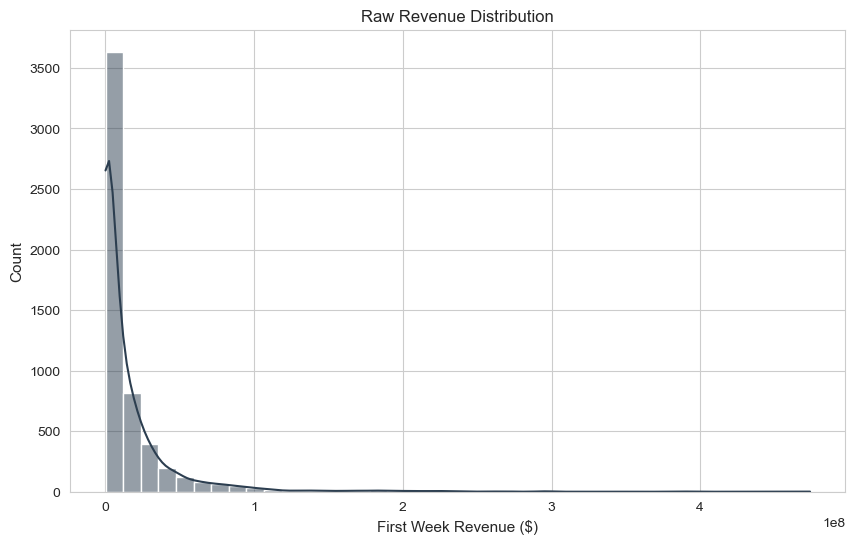

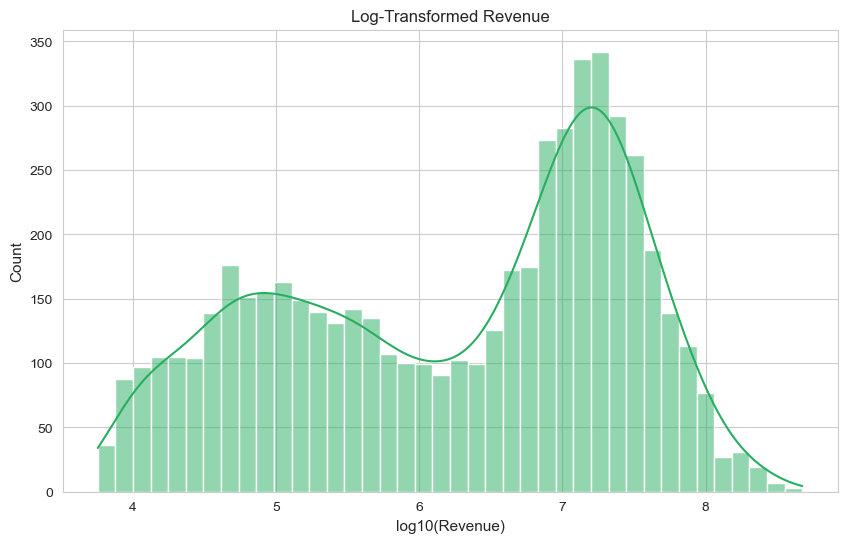

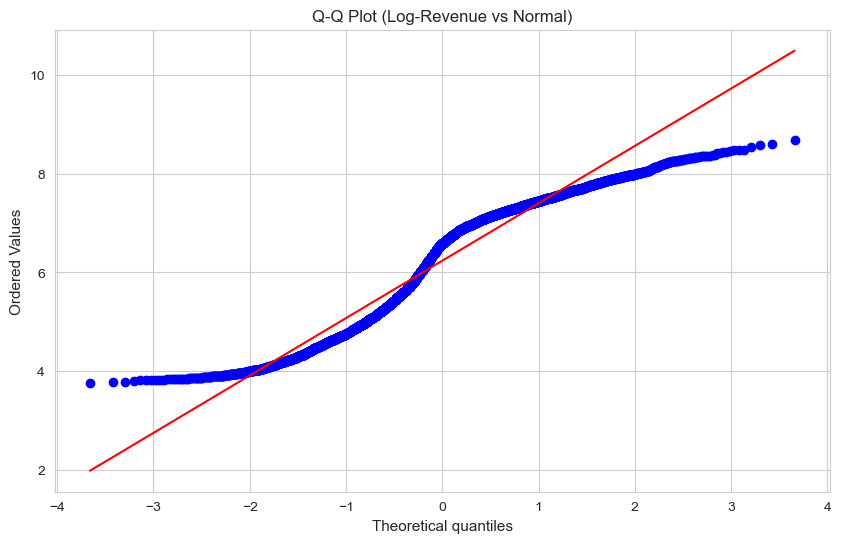

2025-12-15 14:32:13 [INFO] revenue_first_week_raw_movie stats (positive only): min=5690, median=3839975, 90th=40518950, max=473894638


In [ ]:
# 4.2 Raw and log distribution of the target variable
TARGET_COL = "revenue_first_week_raw_movie"

if TARGET_COL not in df_filtered.columns:
    logger.error("Target column '%s' not found in df_filtered. Cannot run target EDA.", TARGET_COL)
else:
    # a. Raw distribution (Dark Blue #2c3e50)
    plt.figure(figsize=(10, 6))
    sns.histplot(df_filtered[TARGET_COL], bins=40, kde=True, color='#2c3e50')
    plt.title("Raw Revenue Distribution")
    plt.xlabel("First Week Revenue ($)")
    plt.show()

    # Log distribution logic (using log10 for interpretability)
    target_positive = df_filtered[df_filtered[TARGET_COL] > 0][TARGET_COL]

    if target_positive.empty:
        logger.error(
            "No positive values in '%s'; cannot plot log-scale distribution.", TARGET_COL
        )
    else:
        # Temporary variable (not saved to DF)
        log_vals = np.log10(target_positive)

        # b. Log distribution (Green #27ae60)
        plt.figure(figsize=(10, 6))
        sns.histplot(log_vals, bins=40, kde=True, color='#27ae60')
        plt.title("Log-Transformed Revenue")
        plt.xlabel("log10(Revenue)")
        plt.show()

        # c. Q-Q Plot (New Addition)
        plt.figure(figsize=(10, 6))
        stats.probplot(log_vals, dist="norm", plot=plt)
        plt.title("Q-Q Plot (Log-Revenue vs Normal)")
        plt.show()

        logger.info(
            "%s stats (positive only): min=%.0f, median=%.0f, 90th=%.0f, max=%.0f",
            TARGET_COL,
            target_positive.min(),
            target_positive.median(),
            np.percentile(target_positive, 90),
            target_positive.max(),
        )

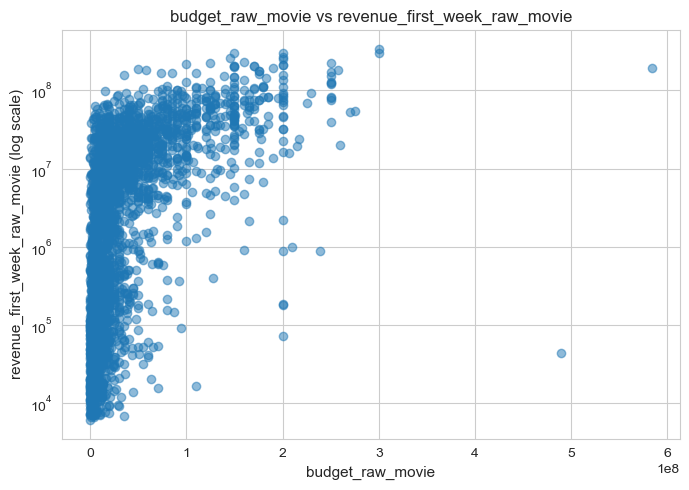

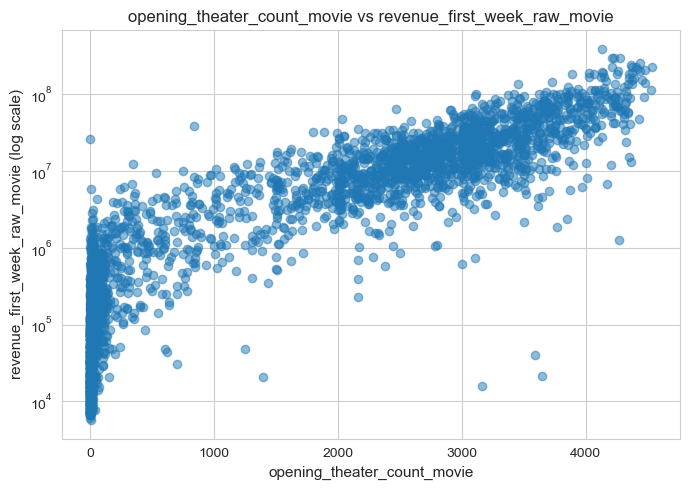

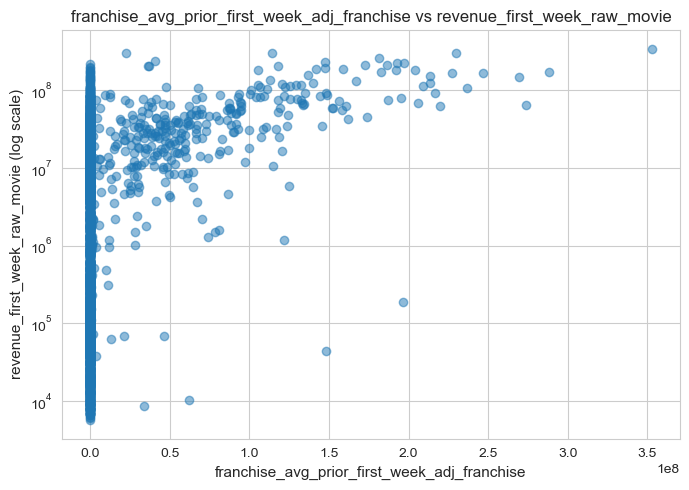

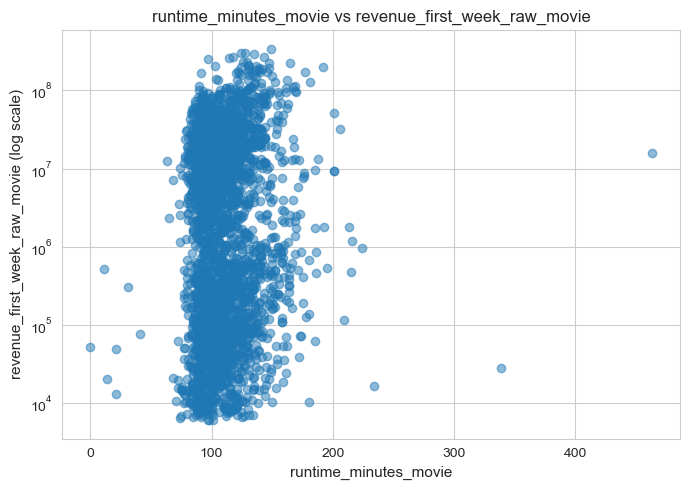

In [442]:
# 4.3 Key numeric features vs target plots
# Define key numeric features to plot against the target
key_numeric_features = [
    "budget_raw_movie",
    "opening_theater_count_movie",
    "franchise_avg_prior_first_week_adj_franchise",
    "runtime_minutes_movie",
]

for feat in key_numeric_features:
    if feat in df_filtered.columns:
        safe_scatter_with_target(
            df_filtered,
            feature_col=feat,
            target_col=TARGET_COL,
            sample_size=3000,   # safe even if you later scale up
            log_x=True if feat in {"production_budget_usd", "opening_theaters", "total_theaters"} else False,
            log_y=True,
            title=f"{feat} vs {TARGET_COL}",
        )
    else:
        logger.warning("Feature '%s' not found; skipping scatter vs target.", feat)


2025-12-15 14:32:14 [INFO] Categorical EDA for 'is_franchise_franchise'
2025-12-15 14:32:14 [WARNING] Column 'is_franchise_franchise' is numeric; treating it as categorical may be misleading.
2025-12-15 14:32:14 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-15 14:32:14 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


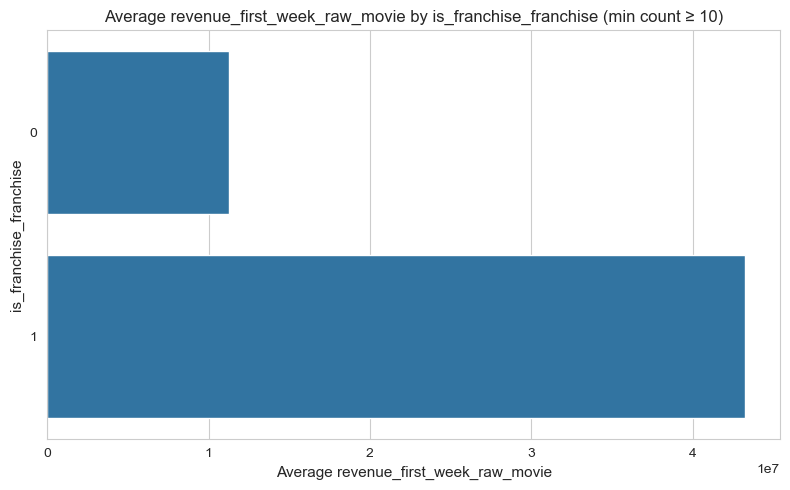

,is_franchise_franchise,mean_target,median_target,count
1,1,"43,258,925.77","24,331,557.50",684
0,0,"11,242,080.13","2,290,780.00",4795


2025-12-15 14:32:14 [INFO] Categorical EDA for 'mpaa_rating_movie'


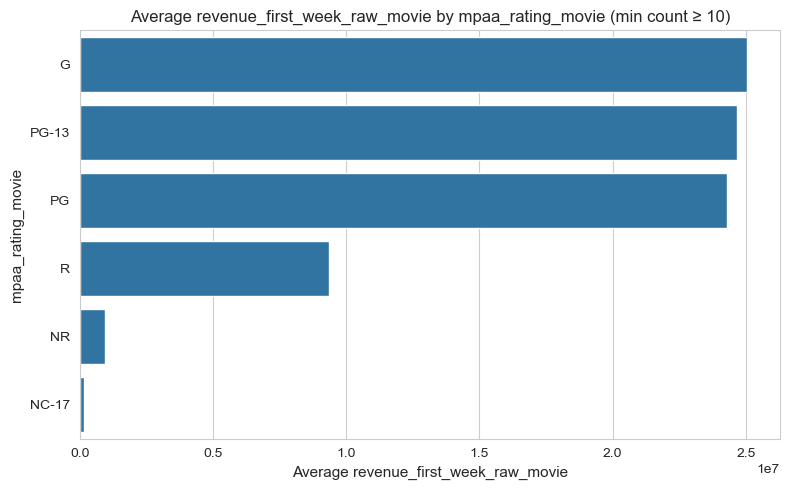

,mpaa_rating_movie,mean_target,median_target,count
0,G,"25,029,150.54","12,548,471.00",90
4,PG-13,"24,662,468.10","11,719,690.00",1773
3,PG,"24,280,442.04","12,140,180.00",673
6,R,"9,360,567.39","1,336,616.50",2218
2,NR,"944,299.76","54,503.00",217
1,NC-17,"166,133.09","132,555.00",11


2025-12-15 14:32:14 [INFO] Categorical EDA for 'original_language_movie'


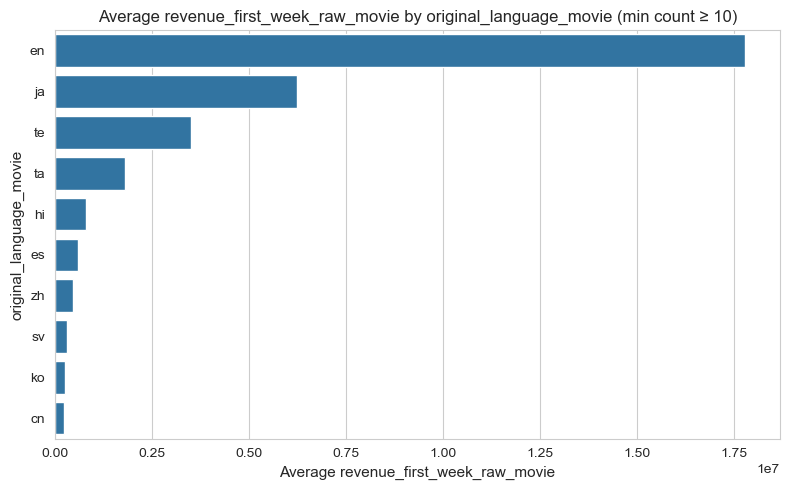

,original_language_movie,mean_target,median_target,count
10,en,"17,787,873.08","7,152,000.00",4656
24,ja,"6,243,819.98","381,136.00",42
39,te,"3,497,829.86","1,320,000.00",21
38,ta,"1,795,626.82","1,770,000.00",11
17,hi,"808,416.25","474,670.00",215
11,es,"602,184.41","69,152.00",75
46,zh,"472,650.84","99,748.00",64
37,sv,"311,301.64","75,058.00",11
26,ko,"263,243.77","72,845.50",52
5,cn,"227,321.72","133,745.50",18


In [443]:
# 4.4 Categorical analysis: franchise, MPAA rating, language
# Define categorical columns to analyze
categorical_cols = [
    "is_franchise_franchise",
    "mpaa_rating_movie",
    "original_language_movie",
]

for cat_col in categorical_cols:
    if cat_col in df_filtered.columns:
        logger.info("Categorical EDA for '%s'", cat_col)
        plot_categorical_target_stats(
            df_filtered,
            cat_col=cat_col,
            target_col=TARGET_COL,
            top_n=10,
            min_count=10,
        )
    else:
        logger.warning("Categorical column '%s' not found; skipping.", cat_col)



Genre Performance Analysis...


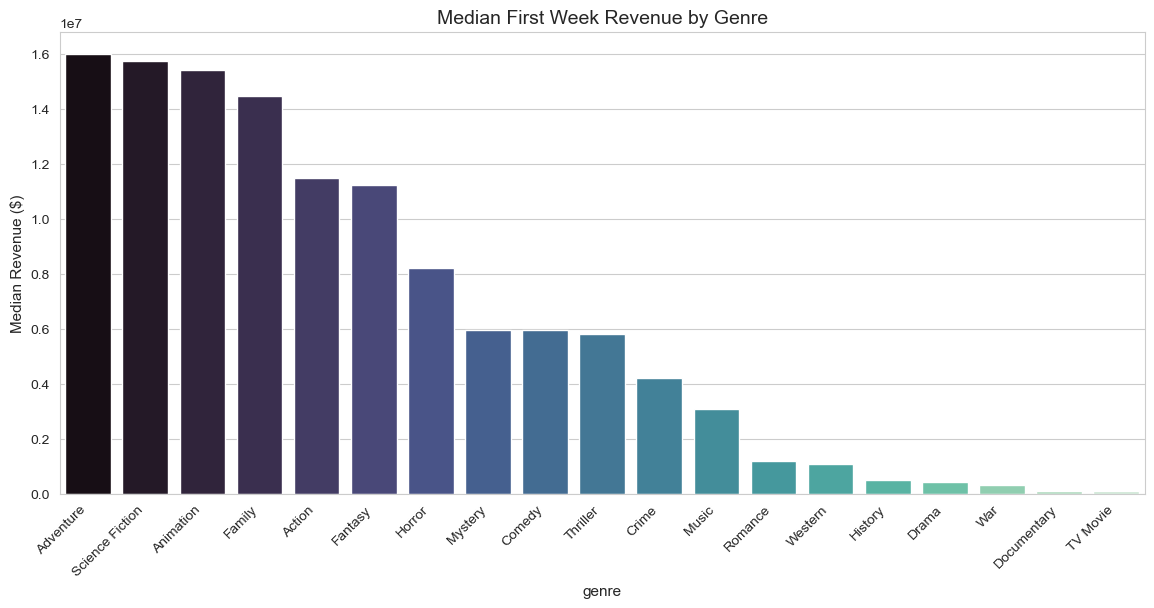

In [ ]:
# 4.5 Genre performance analysis
print("\nGenre Performance Analysis...")

# Create a temporary dataframe where genres are separated
df_genre_exploded = df_filtered.assign(genre=df_filtered['genres_movie'].str.split('|')).explode('genre')

# Calculate median revenue by genre 
genre_perf = df_genre_exploded.groupby('genre')['revenue_first_week_raw_movie'].median().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=genre_perf.index, y=genre_perf.values, palette="mako")
plt.title('Median First Week Revenue by Genre', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Median Revenue ($)')
plt.show()

2025-12-15 14:32:15 [INFO] Top 10 correlations with revenue_first_week_raw_movie:


budget_raw_movie                                    0.66
opening_theater_count_movie                         0.61
franchise_avg_prior_opening_weekend_adj_franchise   0.58
franchise_max_prior_opening_weekend_adj_franchise   0.58
franchise_last_film_opening_weekend_adj_franchise   0.58
franchise_max_prior_first_week_adj_franchise        0.56
franchise_last_film_first_week_adj_franchise        0.56
franchise_avg_prior_first_week_adj_franchise        0.56
franchise_avg_prior_budget_adj_franchise            0.51
franchise_last_film_budget_adj_franchise            0.50
Name: revenue_first_week_raw_movie, dtype: float64

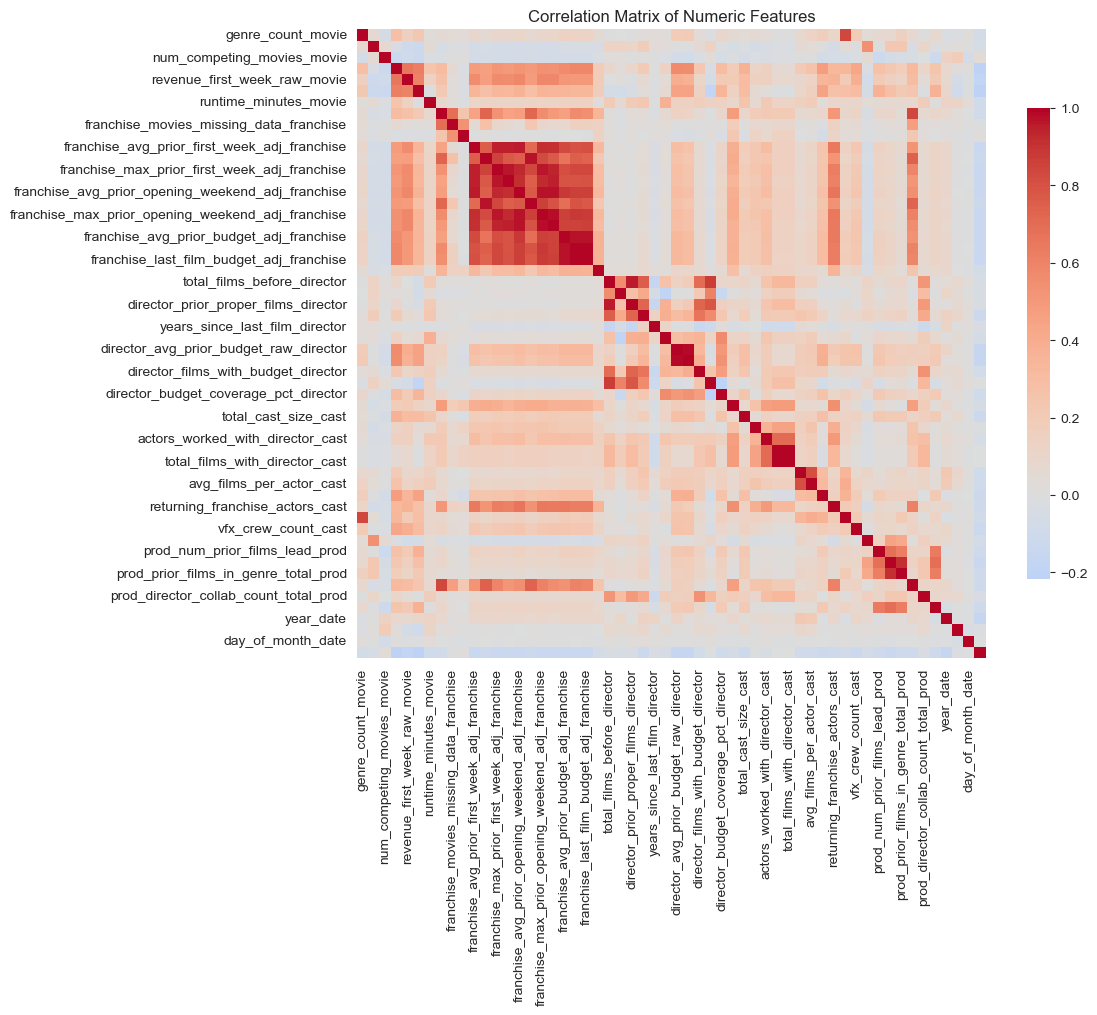

In [445]:
# 4.6 Correlation structure (numeric features)

# Choose numeric columns 
numeric_cols = [
    col for col in df_filtered.columns
    if is_numeric_dtype(df_filtered[col]) and df_filtered[col].nunique() > 5
]

if not numeric_cols:
    logger.warning("No suitable numeric columns found for correlation heatmap.")
else:
    corr_matrix = df_filtered[numeric_cols].corr()

    # Focus on correlations with the target
    if TARGET_COL in corr_matrix.columns:
        target_corr = (
            corr_matrix[TARGET_COL]
            .drop(labels=[TARGET_COL], errors="ignore")
            .sort_values(ascending=False)
        )
        logger.info("Top 10 correlations with %s:", TARGET_COL)
        display(target_corr.head(10))

    plt.figure(figsize=(min(12, 0.6 * len(numeric_cols)), min(10, 0.6 * len(numeric_cols))))
    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        center=0.0,
        square=True,
        cbar_kws={"shrink": 0.75},
    )
    plt.title("Correlation Matrix of Numeric Features")
    plt.tight_layout()
    plt.show()


In [446]:
# 4.7 Top 10 positive and negative correlations with target

TARGET_COL = "revenue_first_week_raw_movie"

if TARGET_COL not in df_filtered.columns:
    logger.error("Target column '%s' not found in DataFrame.", TARGET_COL)
else:
    # Keep only numeric columns (including target)
    numeric_cols = [
        c for c in df_filtered.columns
        if is_numeric_dtype(df_filtered[c]) and df_filtered[c].nunique() > 1
    ]
    if TARGET_COL not in numeric_cols:
        logger.error("Target column '%s' is not numeric.", TARGET_COL)
    else:
        corr_series = (
            raw_df[numeric_cols]
            .corr()[TARGET_COL]
            .drop(labels=[TARGET_COL], errors="ignore")
            .dropna()
            .sort_values()
        )

        # Bottom 10 = most negative, Top 10 = most positive
        neg_corr = corr_series.head(10)
        pos_corr = corr_series.tail(10)[::-1]  # reverse for descending

        logger.info("Top 10 negatively correlated features with %s:", TARGET_COL)
        display(neg_corr.to_frame("correlation"))

        logger.info("Top 10 positively correlated features with %s:", TARGET_COL)
        display(pos_corr.to_frame("correlation"))


2025-12-15 14:32:15 [INFO] Top 10 negatively correlated features with revenue_first_week_raw_movie:


,correlation
is_weekend_date,-0.16
day_of_week_date,-0.15
num_competing_movies_movie,-0.09
director_films_missing_budget_director,-0.06
country_count_movie,-0.03
quarter_date,-0.03
is_holiday_release_date,-0.03
month_date,-0.03
is_pandemic_release_date,-0.02
franchise_movies_missing_budget_franchise,-0.01


2025-12-15 14:32:15 [INFO] Top 10 positively correlated features with revenue_first_week_raw_movie:


,correlation
budget_raw_movie,0.70
opening_theater_count_movie,0.65
franchise_last_film_opening_weekend_adj_franchise,0.59
franchise_avg_prior_opening_weekend_adj_franchise,0.59
franchise_max_prior_opening_weekend_adj_franchise,0.59
franchise_max_prior_first_week_adj_franchise,0.57
franchise_last_film_first_week_adj_franchise,0.57
franchise_avg_prior_first_week_adj_franchise,0.57
franchise_avg_prior_budget_adj_franchise,0.53
franchise_last_film_budget_adj_franchise,0.52


2025-12-15 14:32:15 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-15 14:32:15 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.



Seasonality Analysis: Revenue by Month


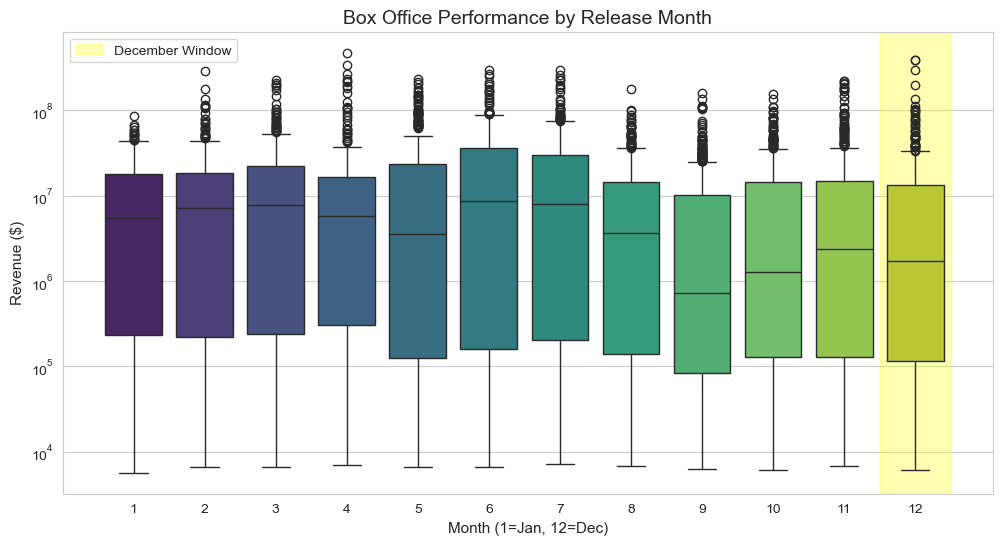

In [447]:
# 4.8 Seasonality analysis: revenue by month
print("\nSeasonality Analysis: Revenue by Month")

if 'month_date' in raw_df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='month_date', y=TARGET_COL, data=df_filtered, palette="viridis")
    plt.title('Box Office Performance by Release Month', fontsize=14)
    plt.xlabel('Month (1=Jan, 12=Dec)')
    plt.ylabel('Revenue ($)')
    plt.yscale('log')  # Log scale to handle outliers

    # Highlight December (Avatar's Month)
    plt.axvspan(10.5, 11.5, color='yellow', alpha=0.3, label='December Window')
    plt.legend()
    plt.show()

In [ ]:
# 4.9 Multicollinearity check (numeric features)

high_corr_threshold = 0.85

# Select numeric feature columns (excluding target)
numeric_df = df_filtered.select_dtypes(include=[np.number]).copy()

cols_to_exclude = [TARGET_COL] 
feature_cols = [c for c in numeric_df.columns if c not in cols_to_exclude]

if len(feature_cols) < 2:
    logger.warning("Not enough numeric features for multicollinearity check.")
else:
    # Correlation matrix (absolute values)
    corr_matrix = numeric_df[feature_cols].corr().abs()

    # Upper triangle to avoid duplicate pairs
    upper = corr_matrix.where(
        np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    )

    # Correlation with target as a simple 'importance' proxy
    target_corr = {}
    if TARGET_COL in df_filtered.columns:
        for col in feature_cols:
            if df_filtered[col].nunique() > 1: 
                target_corr[col] = abs(df_filtered[[col, TARGET_COL]].corr().loc[col, TARGET_COL])
            else:
                target_corr[col] = np.nan
    else:
        logger.warning("Target column '%s' not found; suggestions will ignore predictive value.", TARGET_COL)
        target_corr = {col: np.nan for col in feature_cols}

    # Gather collinear pairs and suggest drops
    collinear_pairs = []
    for col in upper.columns:
        high_corr_features = upper.index[upper[col] > high_corr_threshold].tolist()
        for feat in high_corr_features:
            corr_val = upper.loc[feat, col]
            feat_score = target_corr.get(feat, np.nan)
            col_score = target_corr.get(col, np.nan)

            # Suggest dropping the one with lower absolute correlation with target
            if not np.isnan(feat_score) and not np.isnan(col_score):
                suggested_drop = feat if feat_score < col_score else col
            else:
                suggested_drop = None  # no suggestion if we lack target info

            collinear_pairs.append({
                "feature_1": feat,
                "feature_2": col,
                "correlation": corr_val,
                "feature_1_abs_corr_with_target": feat_score, 
                "feature_2_abs_corr_with_target": col_score,
                "suggested_feature_to_drop": suggested_drop,
            })

    if not collinear_pairs:
        logger.info("✅ No highly collinear feature pairs found (>|%.2f|).", high_corr_threshold)
    else:
        results_df = (
            pd.DataFrame(collinear_pairs)
            .sort_values(by="correlation", ascending=False)
            .reset_index(drop=True)
        )

        logger.info(
            "MULTICOLLINEARITY CHECK: Found %d pairs with |corr| > %.2f",
            len(results_df), high_corr_threshold
        )
        display(results_df)

        # Deduplicated suggestion list
        suggested_drops = sorted(
            {f for f in results_df["suggested_feature_to_drop"].dropna()}
        )

        logger.info("Suggested features to consider dropping (based on lower |corr with target|):")
        display(pd.Series(suggested_drops, name="suggested_drop_candidates"))


# 5. Feature Engineering

Raw unstructured data contains latent signals that are invisible to standard machine learning algorithms. To maximize predictive power, we must transition from data cleaning to Feature Engineering. This process involves converting categorical text and temporal metadata into dense numerical representations. This section focuses on synthesizing these inputs into a mathematical matrix, ensuring the model can interpret complex relationships, such as the interaction between specific genres and release windows, that would otherwise remain obscured

* **5.1 Working Copy:** A separate copy of the filtered dataset is created to ensure that the original clean data remains untouched while new features are experimented with.

* **5.2 Genre & Rating Encodings:** Models require numbers, not words. 
    
    This block converts categorical text into numerical flags. 
    * **Genres:** Since a movie can be "Action" AND "Sci-Fi", the code splits these strings and creates a separate binary column for each genre (e.g., `genre_action: 1`, `genre_comedy: 0`).
    * **MPAA Ratings:** Ratings like "PG-13" or "R" are converted into "Dummy Variables" (binary flags), allowing the model to measure the specific impact of each rating category.

* **5.3 Advanced Domain Features:** This section generates complex, "smart" features based on domain knowledge:
    * **Director Experience:** It calculates whether a director is making their debut or is a small-scale filmmaker.
    * **Production Fit:** It measures the overlap between a studio's expertise and the movie's genre (e.g., is this company experienced in making a horror movie?).
    * **Language & Franchise Flags:** It creates simple flags for English-language films and tracks whether franchise history data is missing, which can be a risk factor.

* **5.4 Handling Missing History:** For debut directors, "missing" data (like *Years Since Last Film*) isn't an error—it simply doesn't exist. This code logically fills these specific gaps with zeros (implying no prior history) rather than using an average, which would be inaccurate for a newcomer.

* **5.5 Log Transformation (Monetary Features):** Financial variables like **Budget** and **Franchise Revenue** often span huge ranges (from thousands to billions). This block applies a logarithmic transformation to these columns. This "squashes" the massive values, reducing the impact of outliers and making the data easier for the model to process mathematically.

* **5.6 Dropping Redundant Columns:** After extracting the useful numbers, the original raw text columns and highly correlated redundant features are removed. This reduces "noise" and prevents the model from cheating or getting confused by duplicate information.

* **5.7 Dropping Avatar 2 for Upliift Calculation** Avatar 2 is dropped from the training dataset, because it'll be used later to predict Avatar 2 with the tuned model, and the scale of error will be used to adjust the prediction for Avatar 3.

In [ ]:
# 5.1 Create working copy for feature engineering

df = df_filtered.copy()
logger.info("Feature engineering starting from df with shape %s", df.shape)


In [ ]:
# 5.2 Genre & MPAA rating encodings

from sklearn.feature_extraction.text import CountVectorizer

GENRE_COL = "genres_movie"
RATING_COL = "mpaa_rating_movie"

logger.info("Starting genre and rating encodings...")

# --- Genre encoding ---
if GENRE_COL in df.columns:
    df[GENRE_COL] = df[GENRE_COL].fillna("")

    # Split on '|' so multi-genre strings become multi-label binary features
    vectorizer = CountVectorizer(
        tokenizer=lambda x: x.split("|"),
        token_pattern=None,
    )
    genre_matrix = vectorizer.fit_transform(df[GENRE_COL])

    genre_feature_names = [
        f"genre_{g.lower().replace(' ', '_')}"
        for g in vectorizer.get_feature_names_out()
    ]
    genre_df = pd.DataFrame(
        genre_matrix.toarray(),
        columns=genre_feature_names,
        index=df.index,
    )

    df = pd.concat([df, genre_df], axis=1)
    logger.info("Created %d genre features.", len(genre_feature_names))
else:
    logger.warning("Column '%s' not found. Skipping genre encoding.", GENRE_COL)

# MPAA rating encoding
if RATING_COL in df.columns:
    df[RATING_COL] = df[RATING_COL].fillna("NR").replace("PG-13 ", "PG-13")  # Not Rated / missing bucket

    rating_dummies = pd.get_dummies(
        df[RATING_COL],
        prefix="rating",
        dtype=int,
    )
    df = pd.concat([df, rating_dummies], axis=1)

    logger.info("Created %d rating dummy features.", rating_dummies.shape[1])
else:
    logger.warning("Column '%s' not found. Skipping rating encoding.", RATING_COL)

logger.info("After genre & rating encoding, df shape: %s", df.shape)


In [ ]:
# 5.3 Advanced director and content features

import re
logger.info("Generating advanced director/content features")

# A. Director experience flags
experience_cols = [
    "director_prior_short_films_director",
    "director_films_with_budget_director",
    "director_films_missing_budget_director",
]

if all(col in df.columns for col in experience_cols):
    total_activity = df[experience_cols].fillna(0).sum(axis=1)

    df["is_debut_director"] = (total_activity == 0).astype(int)
    df["is_smallscale_director"] = (
        (total_activity > 0)
        & (df["director_films_with_budget_director"].fillna(0) == 0)
    ).astype(int)

    logger.info("Director experience flags created: is_debut_director, is_smallscale_director.")
else:
    missing = [c for c in experience_cols if c not in df.columns]
    logger.warning(
        "Skipping director experience flags; missing columns: %s", missing
    )

# B. Production genre match score (studio specialization vs movie genre)

def _clean_genre_token(token: str) -> str:
    # Remove "(N)" counts from strings like "Horror(5)"
    return re.sub(r"\(\d+\)", "", str(token)).strip()

def _calculate_genre_match(row, movie_col: str, prod_col: str) -> int:
    if pd.isna(row.get(movie_col)) or pd.isna(row.get(prod_col)):
        return 0

    movie_genres = {g.strip() for g in str(row[movie_col]).split("|") if g.strip()}
    prod_raw = str(row[prod_col]).split("|")
    prod_genres = {_clean_genre_token(g) for g in prod_raw if g.strip()}

    return len(movie_genres.intersection(prod_genres))

if "genres_movie" in df.columns and "top_3_genres_prod" in df.columns:
    raw_df["prod_genre_match_score"] = raw_df.apply(
        _calculate_genre_match,
        axis=1,
        movie_col="genres_movie",
        prod_col="top_3_genres_prod",
    )
    logger.info("Production genre match score created: prod_genre_match_score.")
else:
    logger.warning(
        "Skipping prod_genre_match_score; required columns 'genres_movie' and/or "
        "'top_3_genres_prod' not found."
    )

# C. English-language flag
if "original_language_movie" in df.columns:
    df["is_english_movie"] = (df["original_language_movie"] == "en").astype(int)
    logger.info("Created is_english_movie flag.")
else:
    logger.warning("Column 'original_language_movie' not found. Skipping is_english_movie.")

# D. Franchise missing data flag
if ("franchise_movies_missing_data_franchise" in df.columns) and ("franchise_movies_missing_budget_franchise" in df.columns):
    df["franchise_history_incomplete"] = (
        (df["franchise_movies_missing_data_franchise"] == 1) | (df["franchise_movies_missing_budget_franchise"] == 1)
    ).astype(int)
    logger.info("Created franchise_history_incomplete flag.")
else:
    logger.warning("Missing columns for franchise_history_incomplete feature.")

logger.info("After advanced features, df shape: %s", df.shape)

In [ ]:
# 5.4 Handle missing values in director-related features
cols_to_fix = [
    'director_prior_short_films_director',
    'director_prior_proper_films_director',
    'years_active_director',
    'years_since_last_film_director',
    'avg_runtime_L10_director',
    'director_avg_prior_budget_adj_director',
    'director_films_with_budget_director',
    'director_films_missing_budget_director',
    'director_prior_franchise_films_director',
]

# Fill 0 ONLY for debut directors (Debut = No History)
df.loc[df['is_debut_director'] == 1, cols_to_fix] = df.loc[df['is_debut_director'] == 1, cols_to_fix].fillna(0)

# Safety Check (Fill any remaining NaNs with 0 just in case)
df[cols_to_fix] = df[cols_to_fix].fillna(0)

print(" Missing values handled correctly.")

In [ ]:
# 5.5 Log transformation of monetary features

logger.info("Applying log transformations...")

log_money_cols = [
    "budget_raw_movie",
    "franchise_avg_prior_opening_weekend_adj_franchise",
    "director_avg_prior_budget_adj_director",
    "avg_budget_L10_cast",
    "franchise_avg_prior_budget_adj_franchise",
]

for col in log_money_cols:
    if col in df.columns:
        df[f"log_{col}"] = np.log1p(df[col].astype(float))
        logger.info("Created log-transformed feature: log_%s", col)

# DROP RAW MONEY COLUMNS
df.drop(columns=log_money_cols, inplace=True)

logger.info("Dropped raw monetary columns after log transform.")
logger.info("Final df shape: %s", df.shape)


In [ ]:
# 5.6 Drop Specific Multicollinear & Raw Columns
print("\n--- Cleaning: Dropping Specified Raw Columns ---")
    
# List of columns provided to drop
cols_to_drop_patterns = [
    "director_avg_prior_budget_raw_director", "franchise_avg_prior_first_week_adj_franchise", 'top_3_genres_prod',
    "franchise_last_film_budget_adj_franchise", "franchise_last_film_first_week_adj_franchise", "franchise_last_film_opening_weekend_adj_franchise",
    "franchise_max_prior_budget_adj_franchise", "franchise_max_prior_first_week_adj_franchise", "franchise_max_prior_opening_weekend_adj_franchise",
    "franchise_sum_prior_first_week_adj_franchise", "franchise_sum_prior_opening_weekend_adj_franchise", "quarter_date", "prod_prior_films_in_genre_total_prod",
    "total_films_before_director", "original_language_movie", "genres_movie", "production_countries_movie", "release_date_movie", "budget_class_movie",
    "director_budget_coverage_pct_director", "top_3_genres_director", "total_films_with_director_cast", "top_3_genres_cast", 'lead_company_prod', 
    'franchise_movies_missing_data_franchise', 'franchise_movies_missing_budget_franchise', 'mpaa_rating_movie'
]       
df.drop(columns=cols_to_drop_patterns, inplace=True)
print(f" Dropped {len(cols_to_drop_patterns)} raw/redundant columns.")

logger.info("After removing features, df shape: %s", df.shape) 

In [ ]:
# 5.7 Remove Avatar 2 for Uplift Calculation
# Set up logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# Find Avatar 2 row
logging.info("Searching for Avatar 2 in the dataset...")

# Search for Avatar 2 (trying multiple possible title variations)
avatar_2_mask = df['title_movie'].str.contains('Avatar.*2|Avatar:.*Way.*Water', case=False, na=False, regex=True)

if avatar_2_mask.sum() == 0:
    # Try exact match variations
    possible_titles = [
        'Avatar 2',
        'Avatar: The Way of Water',
        'Avatar The Way of Water',
        'The Way of Water'
    ]
    for title in possible_titles:
        avatar_2_mask = df['title_movie'].str.contains(title, case=False, na=False, regex=False)
        if avatar_2_mask.sum() > 0:
            break

# Check if found
if avatar_2_mask.sum() == 0:
    logging.error("Avatar 2 not found in the dataset!")
    logging.info(f"Available titles sample: {df['title_movie'].head(20).tolist()}")
else:
    # Extract Avatar 2 row
    avatar_2_df = df[avatar_2_mask].copy()
    
    logging.info(f"✓ Found Avatar 2! Number of matching rows: {len(avatar_2_df)}")
    logging.info(f"✓ Title: {avatar_2_df['title_movie'].values[0]}")
    logging.info(f"✓ Avatar 2 row index: {avatar_2_df.index.tolist()}")
    
    # Remove Avatar 2 from main dataframe
    df = df[~avatar_2_mask].copy()
    
    logging.info(f"✓ Removed Avatar 2 from main dataframe")
    logging.info(f"✓ Main df shape after removal: {df.shape}")
    logging.info(f"✓ Avatar 2 df shape: {avatar_2_df.shape}")
    
    # Drop title_movie column from both dataframes
    df = df.drop(columns=['title_movie'])
    avatar_2_df = avatar_2_df.drop(columns=['title_movie'])
    
    logging.info(f"✓ Dropped 'title_movie' column from both dataframes")
    logging.info(f"✓ Final main df shape: {df.shape}")
    logging.info(f"✓ Final Avatar 2 df shape: {avatar_2_df.shape}")
    logging.info("Avatar 2 extraction complete!")

## 6.2 Comprehensive Model Training Pipeline

Here, the analysis implements a production-grade modeling pipeline. It involves three sophisticated stages: the instantiation of a diverse algorithm suite (ranging from linear models to gradient boosting), the application of 'Walk-Forward' Cross-Validation to simulate real-world forecasting conditions, and the optimization of a weighted Ensemble. This multi-layered approach ensures that the final prediction is robust against overfitting and capable of generalizing to unseen future data.

### A. The Contenders (Model Suite)
A diverse group of algorithms is selected to ensure no pattern is missed. Each has a specific strength:

1.  **Tree-Based Models (Random Forest, XGBoost, LightGBM, CatBoost):**
    * *Why:* These are the industry standard for tabular data. They work by asking a series of "Yes/No" questions (e.g., "Is budget > $100M?") to form a decision tree.
    * *Strength:* They handle non-linear relationships and interactions between features (e.g., how Genre affects Budget) exceptionally well.
    
2.  **TabPFN (Transformer for Tabular Data):**
    * *Why:* A cutting-edge deep learning model that works similarly to Large Language Models (like GPT) but for numbers.
    * *Strength:* It is specifically designed for smaller datasets (like this one) and often outperforms traditional methods without needing extensive tuning.

3.  **Explainable Boosting Machine (EBM):**
    * *Why:* A "Glass Box" model. Unlike complex "Black Box" AI, EBM allows us to see exactly how much each feature contributed to a specific prediction.
    * *Strength:* High interpretability and safety.

4.  **Classical Baselines (Ridge Regression, KNN, SVR):**
    * *Why:* Simple linear and geometric models.
    * *Strength:* They serve as a sanity check. If a complex AI cannot beat simple Ridge Regression, the complex AI is unnecessary.

### B. Validation Strategy: Blocked Walk-Forward CV
To prevent "cheating" (looking into the future), a **Blocked Walk-Forward Cross-Validation** is used.
* *How it works:* The model trains on a window of time (e.g., 2000-2005) and tests on the next immediate block (2006). The window then expands (2000-2006) to test on the next block (2007), and so on.
* *Goal:* This mimics the actual passage of time, ensuring the model is robust to changing market trends.


### C. Caruana Hill Climbing (Ensemble Optimization)
Rather than relying on a single model, this technique combines the best models into a team (Ensemble).
* *The Logic:* It starts with an empty team. It tests adding every model to the team and keeps the one that reduces the error the most. It repeats this process 200 times.
* *The Benefit:* If LightGBM is good at predicting blockbusters but bad at indie films, and Ridge is the opposite, the Hill Climbing algorithm finds the perfect mathematical weight (e.g., 40% LightGBM + 20% Ridge + 30% TabPFN) to balance their strengths and minimize total error.

**Final Output:** The code concludes by printing a Leaderboard comparing the RMSE (Root Mean Squared Error) of all models on the 2023-2025 Holdout set, and the Caruana Ensemble leads here with EBM, a close second. However, the leaderboard shifted from Cross Validation to Testing, indicating a possible 'Era Shift' coupled with the COVID effect. 

In [ ]:
# 6.1 Train - Test Split
# SPLIT DATA (2000-2022 vs 2023-2025) 
# Save Final CSV
df_final = df.copy()
df_final.to_csv('modeling_avatar_final_dataset.csv', index=False)
print(f"✅ Saved dataset with shape {df_final.shape}")

# Define Features & Target
TARGET_COL = "revenue_first_week_raw_movie"
X = df_final.drop(columns=[TARGET_COL])
y = df_final[TARGET_COL]

# Log-Transform Target
y_log = np.log1p(y)

# Create Time-Based Masks
# Training: 2000-2022 (Learns history + Pandemic recovery)
# Holdout: 2023-2025 (Tests on the "New Normal")
train_mask = X['year_date'] <= 2022
test_mask = X['year_date'] > 2022

# Split Data 
X_train = X[train_mask].copy()
y_train = y_log[train_mask].copy()  

X_holdout = X[test_mask].copy()
y_holdout_log = y_log[test_mask].copy()

# Verify
print("-" * 40)
print(f"✅ Training Set (2000-2022): {X_train.shape[0]} movies")
print(f"✅ Holdout Set  (2023-2025): {X_holdout.shape[0]} movies")
print("-" * 40)
print("READY FOR PIPELINE.")

In [ ]:
# =============================================================================
# Model Training and Evaluation 1
# =============================================================================

print("INITIATING MODEL TRAINING WITH CARUANA HILL ENSEMBLE")
print("-" * 90)

# -----------------------------------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------------------------------
GLOBAL_SEED = globals().get("GLOBAL_SEED", 42)

N_OUTER_SPLITS = 5
MIN_SAMPLES = 50

# Date columns (required)
YEAR_COL  = "year_date"
MONTH_COL = "month_date"
DAY_COL   = "day_of_month_date"

# Blocking unit for CV: year-month 
BLOCK_UNIT = "year_month"  # "year_month" or "date"

# Caruana Hill Climbing
MAX_HILL_ITERATIONS = 200
PATIENCE = 7  # early stop patience
REL_IMPROVEMENT_EPS = 0.0005  # 0.05% relative improvement threshold

# Learn ensemble weights primarily on recent years (uses OOF preds)
ENSEMBLE_CALIBRATION_START_YEAR = 2016
ENSEMBLE_CALIBRATION_END_YEAR   = 2022

# Sanity cutoff: exclude absurdly bad models (CV RMSE > $100M)
ABSURD_RMSE_CUTOFF = 100_000_000

# -----------------------------------------------------------------------------
# REQUIRED INPUTS 
# -----------------------------------------------------------------------------
required = ["X_train", "y_train", "X_holdout", "y_holdout_log"]
missing = [k for k in required if k not in globals()]
if missing:
    raise ValueError(f"CRITICAL: Missing required variables: {missing}")

for col in [YEAR_COL, MONTH_COL, DAY_COL]:
    if col not in X_train.columns:
        raise ValueError(f"CRITICAL: '{col}' not found in X_train columns.")
    if col not in X_holdout.columns:
        raise ValueError(f"CRITICAL: '{col}' not found in X_holdout columns.")

# Convert y objects to aligned Series
y_train = pd.Series(y_train).reset_index(drop=True)
y_holdout_log = pd.Series(y_holdout_log).reset_index(drop=True)
y_holdout_true = np.expm1(y_holdout_log.values)

In [ ]:
# -----------------------------------------------------------------------------
# CHRONOLOGICAL SORTING (FULL DATE)
# -----------------------------------------------------------------------------
print("Preparing and sorting data chronologically")

def build_release_datetime(X: pd.DataFrame) -> pd.Series:
    """Build a stable datetime for ordering (not used as a feature)."""
    yr = pd.to_numeric(X[YEAR_COL], errors="coerce").fillna(1900).astype(int)
    mo = pd.to_numeric(X[MONTH_COL], errors="coerce").fillna(1).astype(int).clip(1, 12)
    dy = pd.to_numeric(X[DAY_COL], errors="coerce").fillna(1).astype(int).clip(1, 31)

    # Safe datetime construction
    dt = pd.to_datetime(
        {"year": yr, "month": mo, "day": dy},
        errors="coerce"
    )

    # If any invalid dates (e.g., Feb 30), coerce to first day of month
    if dt.isna().any():
        dt_fallback = pd.to_datetime({"year": yr, "month": mo, "day": 1}, errors="coerce")
        dt = dt.fillna(dt_fallback)

    return dt

X_train_work = X_train.reset_index(drop=True).copy()
X_holdout_work = X_holdout.reset_index(drop=True).copy()

train_dt = build_release_datetime(X_train_work)
holdout_dt = build_release_datetime(X_holdout_work)

# Sort training set by full date (year, month, day)
sort_idx = train_dt.sort_values().index
X_train_sorted = X_train_work.loc[sort_idx].reset_index(drop=True)
y_train_sorted = y_train.loc[sort_idx].reset_index(drop=True)
train_dt_sorted = train_dt.loc[sort_idx].reset_index(drop=True)

print(f"   Train sorted: {X_train_sorted.shape} | Holdout: {X_holdout_work.shape}")

# -----------------------------------------------------------------------------
# MODEL DEFINITIONS
# -----------------------------------------------------------------------------
def get_model_suite(seed: int = 42) -> dict:
    suite = {
        "Dummy (Mean)": DummyRegressor(strategy="mean"),

        "Ridge": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=1.0)
        ),

        "Random Forest": RandomForestRegressor(
            n_estimators=600,
            random_state=seed,
            n_jobs=-1
        ),

        "LightGBM": lgb.LGBMRegressor(
            n_estimators=1200,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=seed,
            verbosity=-1
        ),

        "XGBoost": xgb.XGBRegressor(
            n_estimators=1200,
            learning_rate=0.03,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=seed,
            n_jobs=-1
        ),

        "CatBoost": cb.CatBoostRegressor(
            iterations=2000,
            learning_rate=0.03,
            depth=6,
            loss_function="RMSE",
            verbose=0,
            random_seed=seed
        ),

        "EBM": ExplainableBoostingRegressor(
            interactions=10,
            outer_bags=8,
            random_state=seed
        ),

        "KNN": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            KNeighborsRegressor(n_neighbors=15)
        ),

        "SVR": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVR(C=3.0, epsilon=0.05)
        ),

        "MLP": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=800, random_state=seed)
        ),
    }

    if TABPFN_AVAILABLE:
        suite["TabPFN"] = TabPFNRegressor(device="cpu", ignore_pretraining_limits=True)
    else:
        logger.warning("TabPFN not available; skipping TabPFN model.")

    return suite

def rmse_dollars_from_log(y_true_log: np.ndarray, y_pred_log: np.ndarray) -> float:
    y_true_d = np.expm1(y_true_log)
    y_pred_d = np.expm1(y_pred_log)
    return float(np.sqrt(mean_squared_error(y_true_d, y_pred_d)))

def rmse_dollars(y_true_d: np.ndarray, y_pred_d: np.ndarray) -> float:
    return float(np.sqrt(mean_squared_error(y_true_d, y_pred_d)))

models = get_model_suite(GLOBAL_SEED)


In [ ]:
# -----------------------------------------------------------------------------
# Step 1: BUILD BLOCKED WALK-FORWARD SPLITS
# -----------------------------------------------------------------------------
print("\nSTEP 1: Creating BLOCKED walk-forward folds...")

if BLOCK_UNIT == "year_month":
    # Block by year-month to prevent within-month leakage
    year = pd.to_numeric(X_train_sorted[YEAR_COL], errors="coerce").fillna(1900).astype(int)
    month = pd.to_numeric(X_train_sorted[MONTH_COL], errors="coerce").fillna(1).astype(int).clip(1, 12)
    blocks = (year * 100 + month).astype(int)  # e.g., 202104
    block_label = "YYYYMM"
else:
    # Block by exact date 
    blocks = train_dt_sorted.dt.strftime("%Y%m%d")
    block_label = "YYYYMMDD"

unique_blocks = np.array(sorted(pd.unique(blocks)))
if len(unique_blocks) <= (N_OUTER_SPLITS + 1):
    raise ValueError(
        f"Not enough unique blocks ({len(unique_blocks)}) for n_splits={N_OUTER_SPLITS}. "
        f"Try reducing N_OUTER_SPLITS or using coarser blocking."
    )

tscv_outer = TimeSeriesSplit(n_splits=N_OUTER_SPLITS)

# Map each fold's train/val blocks into row indices
folds = []
for fold_idx, (blk_tr_idx, blk_va_idx) in enumerate(tscv_outer.split(unique_blocks), start=1):
    tr_blocks = unique_blocks[blk_tr_idx]
    va_blocks = unique_blocks[blk_va_idx]

    tr_mask = np.isin(blocks.values if hasattr(blocks, "values") else blocks, tr_blocks)
    va_mask = np.isin(blocks.values if hasattr(blocks, "values") else blocks, va_blocks)

    train_idx = np.where(tr_mask)[0]
    val_idx = np.where(va_mask)[0]

    folds.append((train_idx, val_idx, tr_blocks, va_blocks))

    # fold summary
    va_years = sorted(pd.unique(X_train_sorted.loc[val_idx, YEAR_COL].astype(int)))
    print(
        f"   Fold {fold_idx}/{N_OUTER_SPLITS}: "
        f"Train rows {len(train_idx):,} -> Valid rows {len(val_idx):,} | "
        f"Valid years: {va_years[0]}..{va_years[-1]} | Block unit: {block_label}"
    )

# -----------------------------------------------------------------------------
# STEP 2: OUTER LOOP - OOF PREDICTIONS FOR BASE MODELS
# -----------------------------------------------------------------------------
print("\nSTEP 2: Running blocked walk-forward CV (OOF predictions)...")

oof_pred_log = {name: np.full(len(y_train_sorted), np.nan, dtype=float) for name in models.keys()}

for fold_idx, (train_idx, val_idx, _, _) in enumerate(folds, start=1):
    X_tr = X_train_sorted.iloc[train_idx]
    X_va = X_train_sorted.iloc[val_idx]
    y_tr = y_train_sorted.iloc[train_idx]

    print(f"   Fold {fold_idx}: Fitting models on {len(train_idx):,} rows; validating on {len(val_idx):,} rows")

    for name, model in models.items():
        try:
            m = clone(model)
            m.fit(X_tr, y_tr)
            pred = m.predict(X_va)
            oof_pred_log[name][val_idx] = pred
        except Exception as e:
            logger.error(f"   Fold {fold_idx}: {name} failed - {str(e)}")

# -----------------------------------------------------------------------------
# STEP 3: BASE MODEL PERFORMANCE REPORT (DOLLAR RMSE)
# -----------------------------------------------------------------------------
print("\nSTEP 3: Base model CV performance (RMSE in $)")
print(f"   {'Model':<22} {'CV RMSE ($)':>15}   Status")
print(f"   {'-'*60}")

cv_results = []
valid_models = []

for name in models.keys():
    pred = oof_pred_log[name]
    mask = ~np.isnan(pred)

    if mask.sum() < MIN_SAMPLES:
        print(f"   {name:<22} {'N/A':>15}   Insufficient OOF points")
        continue

    rmse_cv = rmse_dollars_from_log(y_train_sorted.values[mask], pred[mask])

    if rmse_cv > ABSURD_RMSE_CUTOFF:
        print(f"   {name:<22} ${rmse_cv:>14,.0f}   EXCLUDED (absurdly high)")
        continue

    cv_results.append({"Model": name, "CV_RMSE": rmse_cv})
    valid_models.append(name)
    print(f"   {name:<22} ${rmse_cv:>14,.0f}   OK")

if len(valid_models) < 2:
    logger.warning("Not enough valid models for ensembling; will skip ensemble step.")
    ensemble_weights = {}
    ensemble_cv_rmse = np.nan
else:
    # -----------------------------------------------------------------------------
    # STEP 4: CARUANA HILL CLIMBING 
    # -----------------------------------------------------------------------------
    print("\nSTEP 4: Caruana Hill Climbing (optimize in $ space)")

    # Build OOF matrix (log preds) for valid models
    df_oof = pd.DataFrame({m: oof_pred_log[m] for m in valid_models})
    mask_complete = df_oof.notna().all(axis=1)

    # Focus ensemble-weight learning on recent calibration years
    yrs = pd.to_numeric(X_train_sorted[YEAR_COL], errors="coerce").fillna(0).astype(int)
    calib_mask = (yrs >= ENSEMBLE_CALIBRATION_START_YEAR) & (yrs <= ENSEMBLE_CALIBRATION_END_YEAR)

    final_mask = mask_complete & calib_mask

    if final_mask.sum() < MIN_SAMPLES:
        # fallback to all complete points if calibration window too small
        logger.warning(
            "Calibration window produced too few samples; falling back to all-complete OOF rows."
        )
        final_mask = mask_complete

    # Ensemble training data
    X_ens_log = df_oof.loc[final_mask].values                      
    y_ens_log = y_train_sorted.loc[final_mask].values               

    # Convert to dollars for hill climb 
    X_ens_d = np.expm1(X_ens_log)
    y_ens_d = np.expm1(y_ens_log)

    print(f"   Ensemble weight-learning rows: {len(y_ens_d):,}")
    print(f"   Models considered: {len(valid_models)}")
    print(f"   Calibration years used: {yrs.loc[final_mask].min()}..{yrs.loc[final_mask].max()}")

    model_names = list(valid_models)
    n_models = len(model_names)

    selection_counts = np.zeros(n_models, dtype=float)
    current_sum = np.zeros(len(y_ens_d), dtype=float)

    best_rmse = np.inf
    best_rmse_history = []
    no_improve = 0

    for t in range(1, MAX_HILL_ITERATIONS + 1):
        best_rmse_t = np.inf
        best_idx = None

        # Try adding each model once
        for j in range(n_models):
            test_pred = (current_sum + X_ens_d[:, j]) / t
            r = rmse_dollars(y_ens_d, test_pred)
            if r < best_rmse_t:
                best_rmse_t = r
                best_idx = j

        # Update ensemble
        selection_counts[best_idx] += 1
        current_sum += X_ens_d[:, best_idx]
        best_rmse_history.append(best_rmse_t)

        # Early stopping 
        if best_rmse < np.inf:
            rel_impr = (best_rmse - best_rmse_t) / max(best_rmse, 1e-9)
            if rel_impr < REL_IMPROVEMENT_EPS and t > 15:
                no_improve += 1
            else:
                no_improve = 0
        best_rmse = min(best_rmse, best_rmse_t)

        if (t % 25 == 0) or (t == 1):
            print(f"      Iter {t:3d}: best RMSE ${best_rmse_t:,.0f} (added {model_names[best_idx]})")

        if no_improve >= PATIENCE:
            print(f"      Early stopping at iter {t} (no meaningful improvement for {PATIENCE} rounds)")
            break

    # Weights from selection frequencies
    total = selection_counts.sum()
    weights = selection_counts / total if total > 0 else np.zeros_like(selection_counts)

    # Keep weights > 1%
    ensemble_weights = {model_names[i]: float(w) for i, w in enumerate(weights) if w > 0.01}
    ensemble_cv_rmse = float(best_rmse_history[-1]) if best_rmse_history else np.nan

    print(f"\n   Final Ensemble CV RMSE (calibration rows): ${ensemble_cv_rmse:,.0f}")
    print(f"   Ensemble composition ({len(ensemble_weights)} models):")
    for nm, w in sorted(ensemble_weights.items(), key=lambda x: -x[1]):
        print(f"      - {nm:<22} {w:6.1%}")

# -----------------------------------------------------------------------------
# STEP 5: FINAL HOLDOUT EVALUATION (2023-2025)
# -----------------------------------------------------------------------------
print("\nSTEP 5: Final holdout evaluation (2023-2025) - retrain on full 2000-2022")

holdout_log_preds = {}

for name, model in models.items():
    if name not in valid_models:
        continue
    try:
        m = clone(model)
        m.fit(X_train_sorted, y_train_sorted)
        pred_log = m.predict(X_holdout_work)
        holdout_log_preds[name] = pred_log
        print(f"   OK: {name}")
    except Exception as e:
        logger.error(f"   FAIL: {name} - {str(e)}")

# Ensemble holdout prediction 
if ensemble_weights:
    ens_pred_d = np.zeros(len(y_holdout_true), dtype=float)
    used = 0
    missing = []

    for nm, w in ensemble_weights.items():
        if nm in holdout_log_preds:
            ens_pred_d += w * np.expm1(holdout_log_preds[nm])
            used += 1
        else:
            missing.append(nm)

    if used > 0:
        holdout_log_preds["Optimized Ensemble"] = np.log1p(np.maximum(ens_pred_d, 0.0))  # store as log for uniformity
        if missing:
            logger.warning(f"Ensemble missing components on holdout: {missing}")
    else:
        logger.error("No valid ensemble components available for holdout; skipping ensemble.")

# -----------------------------------------------------------------------------
# STEP 6: FINAL LEADERBOARD
# -----------------------------------------------------------------------------
print("\nFINAL LEADERBOARD (RMSE in $)")
print("=" * 90)

results = []
cv_lookup = {r["Model"]: r["CV_RMSE"] for r in cv_results}

for name, pred_log in holdout_log_preds.items():
    # Holdout RMSE in dollars
    pred_d = np.expm1(pred_log)
    hold_rmse = float(np.sqrt(mean_squared_error(y_holdout_true, pred_d)))
    hold_mae = float(mean_absolute_error(y_holdout_true, pred_d))
    hold_r2  = float(r2_score(y_holdout_true, pred_d))

    # CV RMSE: base models from OOF; ensemble from its calibration CV
    if name == "Optimized Ensemble":
        cv_rmse = ensemble_cv_rmse
    else:
        cv_rmse = cv_lookup.get(name, np.nan)

    results.append({
    "Model": name,
    "Holdout RMSE (2023-25)": hold_rmse,
    "Holdout MAE (2023-25)": hold_mae,
    "Holdout R2 (2023-25)": hold_r2,
    "CV RMSE (blocked, pre-2023)": cv_rmse,
    "Gap (Holdout-CV)": hold_rmse - cv_rmse
    })


df_res = pd.DataFrame(results).sort_values("Holdout RMSE (2023-25)")

pd.options.display.float_format = "${:,.0f}".format
print(df_res[[
    "Model",
    "Holdout RMSE (2023-25)",
    "Holdout MAE (2023-25)",
    "Holdout R2 (2023-25)",
    "CV RMSE (blocked, pre-2023)",
    "Gap (Holdout-CV)"
]].to_string(index=False))

print("=" * 90)

print("\nDIAGNOSTIC SUMMARY")
print("-" * 90)
best = df_res.iloc[0]
print(f"Best model: {best['Model']}")
print(f"Holdout RMSE: ${best['Holdout RMSE (2023-25)']:,.0f}")

if best["Model"] == "Optimized Ensemble":
    base_best = df_res[df_res["Model"] != "Optimized Ensemble"].iloc[0]
    improvement = base_best["Holdout RMSE (2023-25)"] - best["Holdout RMSE (2023-25)"]
    if improvement > 0:
        print(f"Ensemble improvement over best base: ${improvement:,.0f}")
    else:
        print(f"Ensemble underperforms best base by: ${-improvement:,.0f}")
        print(f"Recommendation: use {base_best['Model']} as production baseline.")
print("-" * 90)


INITIATING STRICT TIME-SERIES PIPELINE (BLOCKED CV + DOLLAR CARUANA)
------------------------------------------------------------------------------------------
STEP 0: Preparing and sorting data chronologically...
   Train sorted: (4971, 81) | Holdout: (507, 81)

STEP 1: Creating BLOCKED walk-forward folds...
   Fold 1/5: Train rows 856 -> Valid rows 921 | Valid years: 2004..2007 | Block unit: YYYYMM
   Fold 2/5: Train rows 1,777 -> Valid rows 917 | Valid years: 2007..2011 | Block unit: YYYYMM
   Fold 3/5: Train rows 2,694 -> Valid rows 908 | Valid years: 2011..2015 | Block unit: YYYYMM
   Fold 4/5: Train rows 3,602 -> Valid rows 879 | Valid years: 2015..2019 | Block unit: YYYYMM
   Fold 5/5: Train rows 4,481 -> Valid rows 490 | Valid years: 2019..2022 | Block unit: YYYYMM

STEP 2: Running blocked walk-forward CV (OOF predictions)...
   Fold 1: Fitting models on 856 rows; validating on 921 rows


2025-12-15 14:32:26 [INFO] Creating native dataset
2025-12-15 14:32:28 [INFO] Creating native dataset
2025-12-15 14:32:28 [INFO] Estimating with FAST


   Fold 2: Fitting models on 1,777 rows; validating on 917 rows


2025-12-15 14:33:46 [INFO] Creating native dataset
2025-12-15 14:33:48 [INFO] Creating native dataset
2025-12-15 14:33:48 [INFO] Estimating with FAST


   Fold 3: Fitting models on 2,694 rows; validating on 908 rows


...


STEP 3: Base model CV performance (RMSE in $)
   Model                      CV RMSE ($)   Status
   ------------------------------------------------------------
   Dummy (Mean)           $    34,427,126   OK
   Ridge                  $    25,267,454   OK
   Random Forest          $    20,977,751   OK
   LightGBM               $    19,953,758   OK
   XGBoost                $    21,876,352   OK
   CatBoost               $    21,171,578   OK
   EBM                    $    29,088,354   OK
   KNN                    $    25,514,452   OK
   SVR                    $    24,972,744   OK
   MLP                    $323,818,410,648,813   EXCLUDED (absurdly high)
   TabPFN                 $    19,299,850   OK

STEP 4: Caruana Hill Climbing (optimize in $ space)
   Ensemble weight-learning rows: 1,216
   Models considered: 10
   Calibration years used: 2016..2022
      Iter   1: best RMSE $22,750,299 (added LightGBM)
      Early stopping at iter 22 (no meaningful improvement for 7 rounds)

   Final 

2025-12-15 14:56:35 [INFO] Creating native dataset


   OK: CatBoost


2025-12-15 14:56:42 [INFO] Creating native dataset
2025-12-15 14:56:42 [INFO] Estimating with FAST


   OK: EBM
   OK: KNN
   OK: SVR
   OK: TabPFN

FINAL LEADERBOARD (RMSE in $)
             Model  Holdout RMSE (2023-25)  Holdout MAE (2023-25)  Holdout R2 (2023-25)  CV RMSE (blocked, pre-2023)  Gap (Holdout-CV)
Optimized Ensemble             $25,471,034             $9,383,551                    $1                  $20,776,388        $4,694,645
               EBM             $25,565,764             $9,986,571                    $1                  $29,088,354       $-3,522,590
     Random Forest             $25,807,764             $9,516,306                    $1                  $20,977,751        $4,830,013
          LightGBM             $26,174,880             $9,985,461                    $1                  $19,953,758        $6,221,121
          CatBoost             $26,457,574             $9,729,100                    $1                  $21,171,578        $5,285,995
           XGBoost             $27,117,765             $9,965,269                    $0                  $21,876

# 6.2 Advanced Training with Time-Decay & Era-Weighting

## The Challenge: The "New Normal" Discrepancy
Initial model evaluations often reveal a critical performance gap: models that perform exceptionally well on historical data (2000–2019) frequently degrade when tested on post-2023 releases. This indicates that the cinema industry has undergone a fundamental structural shift due to the pandemic and the rise of streaming services. A "flat" model that treats the market dynamics of 2010 as identical to those of 2024 fails to capture this "New Normal," creating a risk of inaccuracy for future predictions.

## The Objective: Targeting December 2025
The ultimate goal of this project is to forecast the box office performance of *Avatar: Fire and Ash*, scheduled for release in late 2025. To achieve high accuracy for this specific future date, the training pipeline must prioritize recent market behavior over distant historical trends.

## The Solution: Era-Weighted Learning and Time Decay
To address the era shift, this section implements a highly specialized training pipeline.

### a. Exponential Time Decay (Half-Life)
Rather than discarding older data, which still contains valuable lessons about budget and genre correlations, the model utilizes **Sample Weighting** based on recency.

* **Concept:** A "Half-Life" of 72 months (6 years) is applied.
* **Mechanism:** A movie released today is assigned a weight of 1.0. A movie from 6 years ago receives a weight of 0.5, and a movie from 12 years ago drops to 0.25.
* **Justification:** This technique forces the algorithms to "remember" the structural rules of the industry (e.g., big budget = big revenue) while "focusing" intensely on the specific magnitude of the current market.

### b. Explicit Era Splitting (The 40/60 Rule)
Two distinct eras are defined for scoring and optimization:
* **Pre-Shift (< 2023):** Historical stability.
* **Post-Shift (2023+):** The modern recovery phase.
The evaluation metric explicitly assigns **60% importance** to the Post-Shift era and only **40%** to the historical era. This directs optimization algorithms (such as Caruana Hill Climbing) to select models that excel at predicting modern trends, even if it comes at the cost of slightly lower accuracy on older films.

### c. The "Avatar 3" Rehearsal (July–Dec 2025 Holdout)
The validation window is extended to include data up to June 2025. The final Holdout set is strictly defined as **July 2025 – December 2025**. This specific 6-month window serves as a simulation of the exact market environment in which *Avatar 3* will be released, providing the most rigorous possible test of the model's readiness.

Here, EBM secured the best spot inholdout test. This, coupled with it's previous near 1st spot, this is chosen as the best model.

In [ ]:
# =============================================================================
# 6.2 MODEL TRAINING AND EVALUATION 2
# =============================================================================

if not EBM_AVAILABLE:
    raise ImportError("interpret is not available but you required EBM to run. Install: pip install interpret")
if not TABPFN_AVAILABLE:
    raise ImportError("tabpfn is not available but you required TabPFN to run. Install: pip install tabpfn")

# -----------------------------
# CONFIG
# -----------------------------
GLOBAL_SEED = 42

YEAR_COL  = "year_date"
MONTH_COL = "month_date"
DAY_COL   = "day_of_month_date"

# CV evaluation window
CV_START = (2016, 1)
CV_END   = (2025, 6)   # inclusive

# Era split for scoring
ERA_SPLIT = (2023, 1)  # >= 2023-01 is "post"

ERA_WEIGHT_PRE  = 0.40
ERA_WEIGHT_POST = 0.60

# Time-decay (training + eval weighting)
HALF_LIFE_MONTHS = 72  # ~6 years

# Caruana hill-climb
MAX_HILL_ITERS = 200
MIN_HILL_ITERS = 20
PATIENCE = 7
REL_IMPROV_EPS = 0.0005  # 0.05%

# Exclude absurd models by weighted-era RMSE
ABSURD_RMSE_CUTOFF = 100_000_000  # $100M

# Minimum OOF points required for reporting a model
MIN_OOF_POINTS = 200

In [ ]:
# Define Helper Functions
# -----------------------------
# HELPERS
# -----------------------------
def _safe_to_int(s, default=0):
    return pd.to_numeric(s, errors="coerce").fillna(default).astype(int)

def build_datetime(df: pd.DataFrame) -> pd.Series:
    yr = _safe_to_int(df[YEAR_COL], 1900)
    mo = _safe_to_int(df[MONTH_COL], 1).clip(1, 12)
    dy = _safe_to_int(df[DAY_COL], 1).clip(1, 31)

    # Build month start
    month_start = pd.to_datetime({"year": yr, "month": mo, "day": 1}, errors="coerce")
    if month_start.isna().any():
        raise ValueError("Unresolvable year/month in date columns.")

    # Clamp day to that month's max day (fixes Feb 30 etc.)
    month_end = month_start + pd.offsets.MonthEnd(0)
    dy_clamped = np.minimum(dy.values, month_end.dt.day.values)

    dt = pd.to_datetime({"year": yr, "month": mo, "day": dy_clamped}, errors="coerce")
    if dt.isna().any():
        bad = df.loc[dt.isna(), [YEAR_COL, MONTH_COL, DAY_COL]].head(10)
        raise ValueError(f"Unresolvable invalid dates after clamping. Examples:\n{bad}")

    return dt


def ym_int(df: pd.DataFrame) -> np.ndarray:
    yr = _safe_to_int(df[YEAR_COL], 1900).values
    mo = _safe_to_int(df[MONTH_COL], 1).clip(1, 12).values
    return (yr * 100 + mo).astype(int)

def ymlimits_to_int(y_m):
    y, m = y_m
    return int(y) * 100 + int(m)

def safe_expm1(x):
    # robust conversion from log-space -> $
    x = np.asarray(x, dtype=float)
    x = np.clip(x, -50, 50)
    return np.expm1(x)

def weighted_rmse(y, p, w):
    y = np.asarray(y, float); p = np.asarray(p, float); w = np.asarray(w, float)
    w = np.clip(w, 1e-12, None)
    return float(np.sqrt(np.sum(w * (y - p) ** 2) / np.sum(w)))

def weighted_mae(y, p, w):
    y = np.asarray(y, float); p = np.asarray(p, float); w = np.asarray(w, float)
    w = np.clip(w, 1e-12, None)
    return float(np.sum(w * np.abs(y - p)) / np.sum(w))

def weighted_mse(y, p, w):
    y = np.asarray(y, float); p = np.asarray(p, float); w = np.asarray(w, float)
    w = np.clip(w, 1e-12, None)
    return float(np.sum(w * (y - p) ** 2) / np.sum(w))

def weighted_r2(y, p, w):
    y = np.asarray(y, float); p = np.asarray(p, float); w = np.asarray(w, float)
    w = np.clip(w, 1e-12, None)
    y_bar = np.sum(w * y) / np.sum(w)
    ss_res = np.sum(w * (y - p) ** 2)
    ss_tot = np.sum(w * (y - y_bar) ** 2)
    if ss_tot <= 1e-12:
        return float("nan")
    return float(1.0 - ss_res / ss_tot)

def compute_time_decay_weights(dt: pd.Series, anchor_dt: pd.Timestamp, half_life_months=72):
    # continuous months from exact day difference
    dt = pd.to_datetime(dt)
    anchor_dt = pd.to_datetime(anchor_dt)

    age_days = (anchor_dt - dt).dt.total_seconds() / (24 * 3600)
    age_months = (age_days / 30.4375).clip(lower=0)  # avg days/month, continuous
    hl = max(float(half_life_months), 1e-6)
    w = 0.5 ** (age_months / hl)
    return np.asarray(w, float)


In [ ]:
# Prepare data, folds, and models
# -----------------------------
# DATA: combine train + "holdout" to get full data
# -----------------------------
required = ["X_train", "y_train", "X_holdout", "y_holdout_log"]
missing = [k for k in required if k not in globals()]
if missing:
    raise ValueError(f"Missing required variables in memory: {missing}")

X_all = pd.concat([X_train.reset_index(drop=True), X_holdout.reset_index(drop=True)], axis=0).reset_index(drop=True)
y_all_log = pd.concat([pd.Series(y_train).reset_index(drop=True), pd.Series(y_holdout_log).reset_index(drop=True)], axis=0).reset_index(drop=True)

for c in [YEAR_COL, MONTH_COL, DAY_COL]:
    if c not in X_all.columns:
        raise ValueError(f"Missing required date column in features: {c}")

dt_all = build_datetime(X_all)
ym_all = ym_int(X_all)

# Strict chronological sort
# Strict chronological sort (by the constructed datetime)
sort_idx = dt_all.sort_values().index
X_all = X_all.loc[sort_idx].reset_index(drop=True)
y_all_log = y_all_log.loc[sort_idx].reset_index(drop=True)
dt_all = dt_all.loc[sort_idx].reset_index(drop=True)
ym_all = ym_all[sort_idx]

# CV mask: 2016-01 .. 2025-06
ym_start = ymlimits_to_int(CV_START)
ym_end   = ymlimits_to_int(CV_END)
cv_mask = (ym_all >= ym_start) & (ym_all <= ym_end)

if cv_mask.sum() < 200:
    raise ValueError(f"Too few rows in CV window {CV_START}..{CV_END}. Found {cv_mask.sum()}.")

# Era masks within CV
era_split_ym = ymlimits_to_int(ERA_SPLIT)
cv_pre_mask  = cv_mask & (ym_all <  era_split_ym)
cv_post_mask = cv_mask & (ym_all >= era_split_ym)

print("TRAIN+EVAL: Combined dataset")
print(f"  Total rows: {len(X_all):,} | CV rows (2016..2025-09): {cv_mask.sum():,}")
print(f"  CV pre-2023 rows: {cv_pre_mask.sum():,} | CV post-2023 rows: {cv_post_mask.sum():,}")

# -----------------------------
# FOLDS: expanding-by-year
# -----------------------------
years = _safe_to_int(X_all[YEAR_COL], 1900).values
months = _safe_to_int(X_all[MONTH_COL], 1).clip(1, 12).values

folds = []
for vy in range(CV_START[0], CV_END[0] + 1):
    if vy < CV_END[0]:
        va_idx = np.where((years == vy) & cv_mask)[0]
        va_start = pd.Timestamp(vy, 1, 1)
    else:
        # 2025 partial: Jan..Sep
        va_idx = np.where((years == vy) & (months <= CV_END[1]) & cv_mask)[0]
        va_start = pd.Timestamp(vy, 1, 1)

    if len(va_idx) == 0:
        continue

    tr_idx = np.where(dt_all < va_start)[0]
    if len(tr_idx) == 0:
        continue

    folds.append((tr_idx, va_idx, vy))

if len(folds) < 5:
    raise ValueError(f"Too few folds built ({len(folds)}). Check date coverage and CV window.")

print("\nFOLDS (expanding by year; 2025 is Jan..Sep):")
for i, (tr, va, vy) in enumerate(folds, 1):
    print(f"  Fold {i:02d}: val={vy} | train={len(tr):,} rows | val={len(va):,} rows")

# -----------------------------
# MODEL SUITE 
# -----------------------------
imp = SimpleImputer(strategy="median")

def model_suite(seed=42):
    suite = {}

    # 1) Dummy
    suite["Dummy (Mean)"] = DummyRegressor(strategy="mean")

    # 2) Linear 
    suite["Ridge"] = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge()  # defaults
    )

    # 3) Tree ensembles 
    suite["Random Forest"] = RandomForestRegressor(
        random_state=seed,
        n_jobs=-1
    )

    # 4) Boosting libs 
    suite["LightGBM"] = lgb.LGBMRegressor(
        random_state=seed,
        n_jobs=-1,
        verbosity=-1
    )

    suite["XGBoost"] = xgb.XGBRegressor(
        random_state=seed,
        n_jobs=-1,
        tree_method="hist",
        verbosity=0
    )

    suite["CatBoost"] = cb.CatBoostRegressor(
        random_seed=seed,
        verbose=0,
        allow_writing_files=False,
        loss_function="RMSE"
    )

    # 5) Glassbox additive model 
    suite["EBM"] = ExplainableBoostingRegressor(
        random_state=seed
    )

    # 6) KNN 
    suite["KNN"] = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor()  
    )

    suite["SVR"] = make_pipeline(
        StandardScaler(),
        SVR() 
    )

    suite["MLP"] = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            random_state=seed
        )
    )

    # 7) TabPFN 
    suite["TabPFN"] = TabPFNRegressor(
        device="cpu",
        ignore_pretraining_limits=True
    )

    return suite

models = model_suite(GLOBAL_SEED)
print(f"\nMODELS: {len(models)} total")
if not EBM_AVAILABLE:
    print("  Note: EBM not available -> skipped.")
if not TABPFN_AVAILABLE:
    print("  Note: TabPFN not available -> skipped.")

In [ ]:
# Running Cross Validation with Out Of Loop Predidiction and Caruana Hill Climbing
# -----------------------------
# OOF PREDICTIONS (log-space preds; converted to $ only for scoring/ensembling)
# -----------------------------
n = len(X_all)
oof_log = {name: np.full(n, np.nan, dtype=float) for name in models.keys()}
supports_weight = {name: False for name in models.keys()}

def _fit_with_optional_weight(model, Xtr, ytr, sample_weight):
    m = clone(model)

    # Pipeline: route weight param to the *actual* last step name
    if isinstance(m, Pipeline):
        last_step_name = m.steps[-1][0]
        try:
            m.fit(Xtr, ytr, **{f"{last_step_name}__sample_weight": sample_weight})
            return m, True
        except Exception:
            m = clone(model)
            m.fit(Xtr, ytr)
            return m, False

    # Non-pipeline estimator
    try:
        m.fit(Xtr, ytr, sample_weight=sample_weight)
        return m, True
    except Exception:
        m = clone(model)
        m.fit(Xtr, ytr)
        return m, False


print("\nOOF CV: fitting models fold-by-fold (training weights = time-decay)...")
for fi, (tr_idx, va_idx, vy) in enumerate(folds, 1):
    Xtr = X_all.iloc[tr_idx]
    ytr = y_all_log.iloc[tr_idx]
    Xva = X_all.iloc[va_idx]

    # Training weights anchored to the LAST date in training fold (no future peeking)
    anchor_train = dt_all.iloc[tr_idx].max()
    w_tr = compute_time_decay_weights(dt_all.iloc[tr_idx], anchor_train, HALF_LIFE_MONTHS)

    print(f"  Fold {fi:02d} | val={vy} | train={len(tr_idx):,} | val={len(va_idx):,} | anchor_train={anchor_train.date()}")

    for name, model in models.items():
        try:
            m, used_w = _fit_with_optional_weight(model, Xtr, ytr, w_tr)
            supports_weight[name] = supports_weight[name] or used_w
            oof_log[name][va_idx] = m.predict(Xva)
        except Exception as e:
            # leave NaNs in oof_log
            print(f"    - FAIL: {name}: {type(e).__name__}: {e}")

# -----------------------------
# SCORING on OOF rows (2016-2025-09 only), in $ space
# -----------------------------
anchor_eval = pd.Timestamp(CV_END[0], CV_END[1], 1) + pd.offsets.MonthEnd(0)  # 2025-06-30
w_eval_all = compute_time_decay_weights(dt_all, anchor_eval, HALF_LIFE_MONTHS)

cv_idx = np.where(cv_mask)[0]
y_true_d_all = safe_expm1(y_all_log.values)

def era_weighted_metrics(y_d, p_d, w_eval, ym_vals):
    # masks inside the provided arrays 
    pre = (ym_vals < era_split_ym)
    post = (ym_vals >= era_split_ym)

    out = {}

    # If an era is missing, fall back to overall 
    def _safe_group(metric_fn, mask):
        if mask.sum() < 30:
            return np.nan
        return metric_fn(y_d[mask], p_d[mask], w_eval[mask])

    rmse_pre  = _safe_group(weighted_rmse, pre)
    rmse_post = _safe_group(weighted_rmse, post)

    # If one side is NaN, reduce to the other side
    if np.isfinite(rmse_pre) and np.isfinite(rmse_post):
        rmse_sel = ERA_WEIGHT_PRE * rmse_pre + ERA_WEIGHT_POST * rmse_post
    elif np.isfinite(rmse_post):
        rmse_sel = rmse_post
    else:
        rmse_sel = rmse_pre

    out["RMSE_pre"] = rmse_pre
    out["RMSE_post"] = rmse_post
    out["RMSE_sel_40_60"] = rmse_sel

    out["MAE_all"] = weighted_mae(y_d, p_d, w_eval)
    out["MSE_all"] = weighted_mse(y_d, p_d, w_eval)
    out["R2_all"]  = weighted_r2(y_d, p_d, w_eval)

    out["MAE_pre"]  = _safe_group(weighted_mae, pre)
    out["MAE_post"] = _safe_group(weighted_mae, post)

    out["MSE_pre"]  = _safe_group(weighted_mse, pre)
    out["MSE_post"] = _safe_group(weighted_mse, post)

    out["R2_pre"]   = _safe_group(weighted_r2, pre)
    out["R2_post"]  = _safe_group(weighted_r2, post)

    return out

rows = []
valid_models = []
oof_dollars = {}

ym_cv = ym_all[cv_idx]
y_cv_d = y_true_d_all[cv_idx]
w_cv   = w_eval_all[cv_idx]

print("\nSCORES (OOF on 2016..2025-09, in $ space)")
for name, pred_log_full in oof_log.items():
    pred_log_cv = pred_log_full[cv_idx]
    ok = np.isfinite(pred_log_cv)

    if ok.sum() < MIN_OOF_POINTS:
        rows.append({
            "Model": name,
            "Status": f"SKIP (OOF<{MIN_OOF_POINTS})",
        })
        continue

    p_cv_d = safe_expm1(pred_log_cv[ok])
    y_ok_d = y_cv_d[ok]
    w_ok   = w_cv[ok]
    ym_ok  = ym_cv[ok]

    m = era_weighted_metrics(y_ok_d, p_cv_d, w_ok, ym_ok)

    # Exclude absurd
    if (m["RMSE_sel_40_60"] is not None) and np.isfinite(m["RMSE_sel_40_60"]) and (m["RMSE_sel_40_60"] > ABSURD_RMSE_CUTOFF):
        rows.append({
            "Model": name, "Status": "EXCLUDED (absurd RMSE)",
            **{k: m.get(k, np.nan) for k in m}
        })
        continue

    rows.append({
        "Model": name,
        "Status": "OK",
        "Uses_sample_weight_in_fit": bool(supports_weight.get(name, False)),
        **m
    })

    # Save full CV-dollar preds aligned to cv_idx (with NaNs where missing)
    full_cv_pred_d = np.full(len(cv_idx), np.nan, dtype=float)
    full_cv_pred_d[ok] = p_cv_d
    oof_dollars[name] = full_cv_pred_d
    valid_models.append(name)

df_scores = pd.DataFrame(rows)

# Keep OK only for leaderboard sorting
df_ok = df_scores[df_scores["Status"].eq("OK")].copy()
df_ok = df_ok.sort_values("RMSE_sel_40_60", ascending=True)

# Print
def fmt_money(x):
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "NA"
    return f"${x:,.0f}"

print("\nLEADERBOARD (sorted by RMSE_sel_40_60 = 0.4*pre + 0.6*post; all in $)")
show_cols = ["Model", "RMSE_sel_40_60", "RMSE_pre", "RMSE_post", "MAE_all", "MSE_all", "R2_all", "Uses_sample_weight_in_fit"]
for c in show_cols:
    if c not in df_ok.columns:
        df_ok[c] = np.nan

tmp = df_ok[show_cols].copy()
tmp["RMSE_sel_40_60"] = tmp["RMSE_sel_40_60"].map(fmt_money)
tmp["RMSE_pre"] = tmp["RMSE_pre"].map(fmt_money)
tmp["RMSE_post"] = tmp["RMSE_post"].map(fmt_money)
tmp["MAE_all"] = tmp["MAE_all"].map(fmt_money)
tmp["MSE_all"] = tmp["MSE_all"].map(fmt_money)
tmp["R2_all"] = tmp["R2_all"].map(lambda v: "NA" if (not np.isfinite(v)) else f"{v:.4f}")

print(tmp.to_string(index=False))

# ------------------------------------------------------------------------
# CARUANA ENSEMBLE (OOF dollars, optimized on the same weighted-era RMSE)
# ------------------------------------------------------------------------
print("\nCARUANA HILL CLIMBING (OOF $, objective = RMSE_sel_40_60)")

if len(valid_models) < 2:
    print("  Not enough valid models for ensembling.")
    ensemble_weights = {}
    ensemble_metrics = None
else:
    # Build matrix on rows where ALL candidate models have predictions
    pred_mat = pd.DataFrame({m: oof_dollars[m] for m in valid_models})
    complete = pred_mat.notna().all(axis=1).values

    if complete.sum() < MIN_OOF_POINTS:
        # If too strict, drop models with most missing until stable
        miss = pred_mat.isna().mean().sort_values()
        keep = list(miss.index)
        while len(keep) > 2:
            pred_mat2 = pred_mat[keep]
            complete2 = pred_mat2.notna().all(axis=1).values
            if complete2.sum() >= MIN_OOF_POINTS:
                pred_mat = pred_mat2
                complete = complete2
                break
            keep = keep[:-1]

    used_models = list(pred_mat.columns)
    X_ens = pred_mat.loc[complete].values  # dollars
    y_ens = y_cv_d[complete]
    w_ens = w_cv[complete]
    ym_ens = ym_cv[complete]

    def objective_rmse_sel(pred_d):
        m = era_weighted_metrics(y_ens, pred_d, w_ens, ym_ens)
        return m["RMSE_sel_40_60"]

    k = X_ens.shape[1]
    sel = np.zeros(k, dtype=float)
    cur_sum = np.zeros(len(y_ens), dtype=float)

    best = np.inf
    no_imp = 0
    rmse_hist = []

    for t in range(1, MAX_HILL_ITERS + 1):
        best_t = np.inf
        best_j = None
        for j in range(k):
            pred = (cur_sum + X_ens[:, j]) / t
            r = objective_rmse_sel(pred)
            if r < best_t:
                best_t = r
                best_j = j

        sel[best_j] += 1
        cur_sum += X_ens[:, best_j]
        rmse_hist.append(best_t)

        if np.isfinite(best):
            rel = (best - best_t) / max(best, 1e-12)
            if t >= MIN_HILL_ITERS and rel < REL_IMPROV_EPS:
                no_imp += 1
            else:
                no_imp = 0
        if best_t < best:
            best = best_t

        if t in (1, 10, 25, 50, 100, 150, 200):
            print(f"  Iter {t:3d}: RMSE_sel_40_60 = {fmt_money(best_t)} (added {used_models[best_j]})")

        if t >= MIN_HILL_ITERS and no_imp >= PATIENCE:
            print(f"  Early stop at iter {t} (no meaningful improvement for {PATIENCE} rounds)")
            break

    weights = sel / sel.sum()
    ensemble_weights = {used_models[i]: float(weights[i]) for i in range(k) if weights[i] >= 0.01}

    # Final ensemble metrics on the same OOF rows
    ens_pred = (cur_sum / int(sel.sum()))
    ensemble_metrics = era_weighted_metrics(y_ens, ens_pred, w_ens, ym_ens)

    print("\nENSEMBLE WEIGHTS (>=1%):")
    for nm, w in sorted(ensemble_weights.items(), key=lambda x: -x[1]):
        print(f"  {nm:<22}: {w:6.1%}")

    print("\nENSEMBLE OOF METRICS (on common OOF rows, in $):")
    print(f"  RMSE_pre       : {fmt_money(ensemble_metrics['RMSE_pre'])}")
    print(f"  RMSE_post      : {fmt_money(ensemble_metrics['RMSE_post'])}")
    print(f"  RMSE_sel_40_60 : {fmt_money(ensemble_metrics['RMSE_sel_40_60'])}")
    print(f"  MAE_all        : {fmt_money(ensemble_metrics['MAE_all'])}")
    print(f"  MSE_all        : {fmt_money(ensemble_metrics['MSE_all'])}")
    r2v = ensemble_metrics["R2_all"]
    print(f"  R2_all         : {'NA' if not np.isfinite(r2v) else f'{r2v:.4f}'}")

print("\nDONE: This cell completed the new TRAIN+EVAL step (no Optuna).")


TRAIN+EVAL: Combined dataset
  Total rows: 5,478 | CV rows (2016..2025-09): 1,647
  CV pre-2023 rows: 1,216 | CV post-2023 rows: 431

FOLDS (expanding by year; 2025 is Jan..Sep):
  Fold 01: val=2016 | train=3,755 rows | val=265 rows
  Fold 02: val=2017 | train=4,020 rows | val=222 rows
  Fold 03: val=2018 | train=4,242 rows | val=219 rows
  Fold 04: val=2019 | train=4,461 rows | val=180 rows
  Fold 05: val=2020 | train=4,641 rows | val=77 rows
  Fold 06: val=2021 | train=4,718 rows | val=124 rows
  Fold 07: val=2022 | train=4,842 rows | val=129 rows
  Fold 08: val=2023 | train=4,971 rows | val=169 rows
  Fold 09: val=2024 | train=5,140 rows | val=176 rows
  Fold 10: val=2025 | train=5,316 rows | val=86 rows

MODELS: 11 total

OOF CV: fitting models fold-by-fold (training weights = time-decay)...
  Fold 01 | val=2016 | train=3,755 | val=265 | anchor_train=2015-12-31


2025-12-15 15:08:00 [INFO] Creating native dataset
2025-12-15 15:08:06 [INFO] Creating native dataset
2025-12-15 15:08:06 [INFO] Estimating with FAST


  Fold 02 | val=2017 | train=4,020 | val=222 | anchor_train=2016-12-28


2025-12-15 15:15:24 [INFO] Backing off send_request(...) for 0.6s (requests.exceptions.ConnectionError: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)))
2025-12-15 15:15:28 [INFO] Creating native dataset
2025-12-15 15:15:36 [INFO] Creating native dataset
2025-12-15 15:15:36 [INFO] Estimating with FAST


  Fold 03 | val=2018 | train=4,242 | val=219 | anchor_train=2017-12-26


...

  Fold 09 | val=2024 | train=5,140 | val=176 | anchor_train=2023-12-25


2025-12-15 16:21:51 [INFO] Backing off send_request(...) for 0.2s (requests.exceptions.ConnectionError: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)))
2025-12-15 16:21:55 [INFO] Creating native dataset
2025-12-15 16:22:01 [INFO] Creating native dataset
2025-12-15 16:22:01 [INFO] Estimating with FAST


  Fold 10 | val=2025 | train=5,316 | val=86 | anchor_train=2024-12-25


2025-12-15 16:32:00 [INFO] Backing off send_request(...) for 0.7s (requests.exceptions.ConnectionError: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)))
2025-12-15 16:32:04 [INFO] Creating native dataset
2025-12-15 16:32:11 [INFO] Creating native dataset
2025-12-15 16:32:11 [INFO] Estimating with FAST



SCORES (OOF on 2016..2025-09, in $ space)

LEADERBOARD (sorted by RMSE_sel_40_60 = 0.4*pre + 0.6*post; all in $)
        Model RMSE_sel_40_60    RMSE_pre   RMSE_post     MAE_all                MSE_all  R2_all  Uses_sample_weight_in_fit
     LightGBM    $23,946,869 $22,222,705 $25,096,312  $8,697,222   $547,088,356,927,589  0.6493                       True
       TabPFN    $24,394,782 $22,165,156 $25,881,199  $8,260,317   $561,200,070,669,296  0.6402                      False
Random Forest    $24,825,493 $25,234,531 $24,552,801  $9,072,114   $623,492,180,702,792  0.6003                       True
      XGBoost    $25,802,412 $24,470,901 $26,690,086  $9,605,917   $643,278,418,621,307  0.5876                       True
     CatBoost    $25,891,268 $24,632,362 $26,730,538  $8,827,292   $648,948,586,336,930  0.5840                       True
          EBM    $27,190,358 $28,589,507 $26,257,592 $10,204,344   $767,282,815,327,158  0.5081                       True
          KNN    $32,569,

In [ ]:
# =============================================================================
# HOLDOUT TEST (2025-07 - 2025-12)
# =============================================================================

# Sanity: required variables 
need = ["models", "X_all", "y_all_log", "dt_all", "safe_expm1", "compute_time_decay_weights",
        "weighted_rmse", "weighted_mae", "weighted_mse", "weighted_r2",
        "YEAR_COL","MONTH_COL","DAY_COL","GLOBAL_SEED","HALF_LIFE_MONTHS"]
missing = [x for x in need if x not in globals()]
if missing:
    raise ValueError(f"Missing from memory: {missing}")

# Use the Caruana weights learned earlier:
HAS_CARUANA = ("ensemble_weights" in globals()) and isinstance(ensemble_weights, dict) and (len(ensemble_weights) > 0)

# Define holdout window (Avatar 3 "new normal" check)
HOLD_START = pd.Timestamp(2025, 7, 1)
HOLD_END   = pd.Timestamp(2025, 12, 31)

# Build holdout set from X_holdout/y_holdout_log 
need2 = ["X_holdout", "y_holdout_log", "build_datetime"]
missing2 = [x for x in need2 if x not in globals()]
if missing2:
    raise ValueError(f"Missing required holdout variables: {missing2}")

X_h = X_holdout.reset_index(drop=True).copy()
y_h_log = pd.Series(y_holdout_log).reset_index(drop=True)

dt_h = build_datetime(X_h)
hold_mask = (dt_h >= HOLD_START) & (dt_h <= HOLD_END)

if hold_mask.sum() < 30:
    raise ValueError(f"Too few holdout rows in {HOLD_START.date()}..{HOLD_END.date()}: {hold_mask.sum()}")

X_h = X_h.loc[hold_mask].reset_index(drop=True)
y_h_log = y_h_log.loc[hold_mask].reset_index(drop=True)
dt_h = dt_h.loc[hold_mask].reset_index(drop=True)

# Training data 
tr_mask = (dt_all < HOLD_START)
if tr_mask.sum() < 500:
    print(f"Warning: training rows before holdout start are low: {tr_mask.sum()}")

X_tr = X_all.loc[tr_mask].reset_index(drop=True)
y_tr_log = y_all_log.loc[tr_mask].reset_index(drop=True)
dt_tr = dt_all.loc[tr_mask].reset_index(drop=True)

# Training weights anchored to last training date (no future peek)
anchor_train = dt_tr.max()
w_tr = compute_time_decay_weights(dt_tr, anchor_train, HALF_LIFE_MONTHS)

# Evaluation weights anchored to holdout end (emphasize most recent holdout points)
anchor_hold = HOLD_END
w_h = compute_time_decay_weights(dt_h, anchor_hold, HALF_LIFE_MONTHS)

# Helper: fit with optional sample_weight
def _fit_with_optional_weight_local(model, Xtr, ytr, sample_weight):
    m = clone(model)
    if isinstance(m, Pipeline):
        last_step_name = m.steps[-1][0]
        try:
            m.fit(Xtr, ytr, **{f"{last_step_name}__sample_weight": sample_weight})
            return m, True
        except Exception:
            m = clone(model); m.fit(Xtr, ytr)
            return m, False
    try:
        m.fit(Xtr, ytr, sample_weight=sample_weight)
        return m, True
    except Exception:
        m = clone(model); m.fit(Xtr, ytr)
        return m, False

# Evaluate each model
rows = []
preds_hold_d = {}   

y_true_h_d = safe_expm1(y_h_log.values)

print(f"\nHOLDOUT TEST WINDOW: {HOLD_START.date()} .. {HOLD_END.date()}")
print(f"  Holdout rows: {len(X_h):,}")
print(f"  Train rows (dt < {HOLD_START.date()}): {len(X_tr):,} | anchor_train={anchor_train.date()}")

for name, model in models.items():
    try:
        fitted, used_w = _fit_with_optional_weight_local(model, X_tr, y_tr_log, w_tr)
        pred_h_log = fitted.predict(X_h)
        pred_h_d = safe_expm1(pred_h_log)
        preds_hold_d[name] = pred_h_d

        # Unweighted metrics
        rmse = float(np.sqrt(np.mean((y_true_h_d - pred_h_d)**2)))
        mae  = float(np.mean(np.abs(y_true_h_d - pred_h_d)))
        mse  = float(np.mean((y_true_h_d - pred_h_d)**2))

        # Weighted metrics (new-normal sensitive)
        wrmse = weighted_rmse(y_true_h_d, pred_h_d, w_h)
        wmae  = weighted_mae(y_true_h_d, pred_h_d, w_h)
        wmse  = weighted_mse(y_true_h_d, pred_h_d, w_h)
        wr2   = weighted_r2(y_true_h_d, pred_h_d, w_h)

        rows.append({
            "Model": name,
            "Fit_uses_sample_weight": bool(used_w),
            "RMSE_holdout": rmse,
            "MAE_holdout": mae,
            "MSE_holdout": mse,
            "wRMSE_holdout": wrmse,
            "wMAE_holdout": wmae,
            "wMSE_holdout": wmse,
            "wR2_holdout": wr2
        })
    except Exception as e:
        rows.append({"Model": name, "ERROR": f"{type(e).__name__}: {e}"})

df_hold = pd.DataFrame(rows)

# Sort primarily by weighted RMSE 
if "ERROR" in df_hold.columns:
    df_ok = df_hold[df_hold["ERROR"].isna()].copy()
else:
    df_ok = df_hold.copy()

# If everything failed, show the errors and stop
if len(df_ok) == 0:
    print("\nAll models failed on holdout. Here are the errors:")
    print(df_hold[["Model", "ERROR"]].to_string(index=False))
    raise RuntimeError("No successful holdout evaluations.")

# Ensure sorting columns exist
for c in ["wRMSE_holdout", "RMSE_holdout"]:
    if c not in df_ok.columns:
        df_ok[c] = np.nan

df_ok = df_ok.sort_values(["wRMSE_holdout","RMSE_holdout"], ascending=True)

def _fmt(x):
    if x is None or (isinstance(x,float) and not np.isfinite(x)): return "NA"
    return f"${x:,.0f}"

# Build display safely
def _fmt(x):
    if x is None or (isinstance(x,float) and not np.isfinite(x)): return "NA"
    return f"${x:,.0f}"

cols = ["Model","wRMSE_holdout","RMSE_holdout","wMAE_holdout","MAE_holdout","wR2_holdout","Fit_uses_sample_weight"]
for c in cols:
    if c not in df_ok.columns:
        df_ok[c] = np.nan

show = df_ok[cols].copy()
show["wRMSE_holdout"] = show["wRMSE_holdout"].map(_fmt)
show["RMSE_holdout"]  = show["RMSE_holdout"].map(_fmt)
show["wMAE_holdout"]  = show["wMAE_holdout"].map(_fmt)
show["MAE_holdout"]   = show["MAE_holdout"].map(_fmt)
show["wR2_holdout"]   = show["wR2_holdout"].map(lambda v: "NA" if not np.isfinite(v) else f"{v:.4f}")

print("\nHOLDOUT LEADERBOARD (sorted by wRMSE_holdout; $ space):")
print(show.to_string(index=False))

# Evaluate Caruana ensemble on holdout using previously learned ensemble_weights
if HAS_CARUANA:
    # keep only models present in both ensemble_weights and holdout preds
    ens_models = [m for m in ensemble_weights.keys() if m in preds_hold_d]
    if len(ens_models) >= 2:
        w = np.array([ensemble_weights[m] for m in ens_models], float)
        w = w / w.sum()
        ens_pred_h_d = np.sum([w[i] * preds_hold_d[m] for i, m in enumerate(ens_models)], axis=0)

        ens_wrmse = weighted_rmse(y_true_h_d, ens_pred_h_d, w_h)
        ens_wr2   = weighted_r2(y_true_h_d, ens_pred_h_d, w_h)
        ens_rmse  = float(np.sqrt(np.mean((y_true_h_d - ens_pred_h_d)**2)))

        print("\nCARUANA ENSEMBLE on HOLDOUT (using learned weights, $ space):")
        print("  Models used:", ", ".join(ens_models))
        print(f"  wRMSE_holdout: {_fmt(ens_wrmse)} | RMSE_holdout: {_fmt(ens_rmse)} | wR2_holdout: {'NA' if not np.isfinite(ens_wr2) else f'{ens_wr2:.4f}'}")
    else:
        print("\nCARUANA ENSEMBLE on HOLDOUT: Not enough overlapping models to evaluate.")
else:
    print("\nCARUANA ENSEMBLE on HOLDOUT: ensemble_weights not found (or empty). Skipped.")



HOLDOUT TEST WINDOW: 2025-07-01 .. 2025-12-31
  Holdout rows: 76
  Train rows (dt < 2025-07-01): 5,402 | anchor_train=2025-06-27


2025-12-15 16:42:18 [INFO] Backing off send_request(...) for 0.7s (requests.exceptions.ConnectionError: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)))
2025-12-15 16:42:21 [INFO] Creating native dataset
2025-12-15 16:42:28 [INFO] Creating native dataset
2025-12-15 16:42:28 [INFO] Estimating with FAST



HOLDOUT LEADERBOARD (sorted by wRMSE_holdout; $ space):
        Model wRMSE_holdout RMSE_holdout wMAE_holdout MAE_holdout wR2_holdout  Fit_uses_sample_weight
          EBM   $17,709,851  $17,805,579   $7,906,776  $7,939,096      0.7464                    True
        Ridge   $17,887,239  $17,943,915   $8,971,827  $8,992,687      0.7413                    True
     CatBoost   $20,544,755  $20,604,542   $8,379,795  $8,415,396      0.6587                    True
       TabPFN   $21,133,828  $21,141,777   $8,425,949  $8,451,925      0.6389                   False
      XGBoost   $21,341,062  $21,395,954   $8,540,136  $8,566,026      0.6318                    True
     LightGBM   $22,205,475  $22,270,884   $8,920,256  $8,957,902      0.6013                    True
Random Forest   $23,138,050  $23,168,646   $9,291,792  $9,321,907      0.5671                    True
          KNN   $28,226,051  $28,269,033  $13,169,466 $13,185,033      0.3558                   False
          SVR   $29,076,8

2025-12-15 16:54:04 [INFO] Backing off send_request(...) for 0.9s (requests.exceptions.ConnectionError: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)))


# 7. Hyperparameter Tuning (Optuna)

While the previous section compared different models "out of the box," models rarely perform their best with default settings. With tuned hyperparameters for a specific dataset, machine learning models can perform significantly better.

## 7.1 Configuration

This block sets up the tuning environment. It imports **Optuna**, an industry-standard framework for automating the search for the best model settings. It also verifies that all necessary data (era-weighted metrics, time-decay functions) are loaded, ensuring that the tuning process optimizes for the exact same "New Normal" objective defined in Section 6.

## 7.2 Fold Creation & Helper Setup

To tune the model effectively, the code must simulate the training process dozens of times. This section rebuilds the **Blocked Walk-Forward Cross-Validation** structure specifically for the tuning loop.

* **Goal:** Create a reusable "testing ground" where every version of the model is tested on the exact same historical timeline (2016–2025).
* **Metric:** The `rmse_sel_on_cv` function defines the "score" the tuner tries to beat. It strictly uses the **40/60 Era-Weighted RMSE**, forcing Optuna to prefer settings that excel at predicting the post-2023 market.

## 7.3 Tuning the EBM (Explainable Boosting Machine)

This section executes the search for the perfect **Explainable Boosting Machine (EBM)**.

* **The Search Space:** The code defines a range of settings to explore:
    * `learning_rate`: How fast the model learns (too fast misses details; too slow takes forever).
    * `max_bins`: How finely the model divides numerical data (like budget ranges).
    * `interactions`: How many "pairs" of features it should look for (e.g., does "Genre" *plus* "Rating" matter more than the sum of their parts?).

* **The TPE Sampler:** Instead of guessing randomly, Optuna uses a **Tree-structured Parzen Estimator (TPE)**. It learns from previous trials. If a low learning rate yielded a bad score in Trial 1, it will intelligently avoid similar settings in Trial 2, "homing in" on the optimal configuration over 60 trials.

* **Result:** The output is the single best combination of settings that minimized the error on the modern validation set.

In [ ]:
# ============================================================
# 7. OPTUNA HYPERPARAMETER TUNING 
# ============================================================

# 7.1 Configuaration
needed = ["X_all", "y_all_log", "dt_all", "ym_all",
          "safe_expm1", "compute_time_decay_weights", "era_weighted_metrics"]
missing = [k for k in needed if k not in globals()]
if missing:
    raise ValueError(f"Missing required objects: {missing}")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
except Exception as e:
    raise ImportError("interpret is required for EBM. Install: pip install interpret") from e

GLOBAL_SEED = int(globals().get("GLOBAL_SEED", 42))
ERA_SPLIT = globals().get("ERA_SPLIT", (2023, 1))
HALF_LIFE_MONTHS = float(globals().get("HALF_LIFE_MONTHS", 72.0))

# Ensure aligned indexing
X_all_df = X_all.reset_index(drop=True)
y_all_s  = pd.Series(y_all_log).reset_index(drop=True)
dt_all_ts = pd.to_datetime(dt_all).reset_index(drop=True)
ym_all_arr = np.asarray(ym_all)

if not (len(X_all_df) == len(y_all_s) == len(dt_all_ts) == len(ym_all_arr)):
    raise ValueError("X_all, y_all_log, dt_all, ym_all lengths are not aligned.")

In [ ]:
# 7.2 Fold Creation & Helper Setup
# ------------------------------------------------------------
# Build folds covering entire dataset
# ------------------------------------------------------------
years  = pd.to_numeric(X_all_df["year_date"], errors="coerce").fillna(1900).astype(int).values
months = pd.to_numeric(X_all_df["month_date"], errors="coerce").fillna(1).astype(int).clip(1, 12).values

first_year = int(np.nanmin(years))
last_year  = int(np.nanmax(years))
last_month_in_last_year = int(np.nanmax(months[years == last_year]))  # e.g., 11 for 2025-11

# Start cross validation from 2016
AUTO_START_YEAR = int(globals().get("CV_START_YEAR", 2016))
start_year = AUTO_START_YEAR if (AUTO_START_YEAR >= first_year + 1) else (first_year + 1)
start_year = min(start_year, last_year)  # guard

folds = []
for vy in range(start_year, last_year + 1):
    if vy < last_year:
        va_idx = np.where(years == vy)[0]
        va_start = pd.Timestamp(vy, 1, 1)
    else:
        # last year partial: up to last month available 
        va_idx = np.where((years == vy) & (months <= last_month_in_last_year))[0]
        va_start = pd.Timestamp(vy, 1, 1)

    if len(va_idx) == 0:
        continue

    tr_idx = np.where(dt_all_ts < va_start)[0]
    if len(tr_idx) == 0:
        continue

    folds.append((tr_idx, va_idx, vy))

if len(folds) < 5:
    raise ValueError(f"Too few folds built ({len(folds)}). "
                     f"Check date coverage. start_year={start_year}, last_year={last_year}.")

cv_idx = np.unique(np.concatenate([va for (_, va, _) in folds])).astype(int)

# Eval weights anchored to the last date IN THE CV region 
anchor_eval = dt_all_ts.iloc[cv_idx].max()
w_eval_all = compute_time_decay_weights(dt_all_ts, anchor_eval, HALF_LIFE_MONTHS)

ym_cv = ym_all_arr[cv_idx]
y_cv_d = safe_expm1(y_all_s.values[cv_idx])
w_cv   = np.asarray(w_eval_all)[cv_idx]

MIN_OOF = int(globals().get("MIN_OOF_POINTS", 200))

def rmse_sel_on_cv(oof_pred_log_full: np.ndarray) -> float:
    pred_log_cv = np.asarray(oof_pred_log_full)[cv_idx]
    ok = np.isfinite(pred_log_cv)
    if ok.sum() < MIN_OOF:
        return np.inf

    p_d = safe_expm1(pred_log_cv[ok])
    m = era_weighted_metrics(y_cv_d[ok], p_d, w_cv[ok], ym_cv[ok])
    return float(m["RMSE_sel_40_60"])

def oof_predict_log_ebm(model_factory) -> np.ndarray:
    n = len(X_all_df)
    oof = np.full(n, np.nan, dtype=float)

    for (tr_idx, va_idx, vy) in folds:
        Xtr = X_all_df.iloc[tr_idx]
        ytr = y_all_s.iloc[tr_idx]
        Xva = X_all_df.iloc[va_idx]

        # time-decay training weights anchored to last training date (no future peek)
        anchor_train = dt_all_ts.iloc[tr_idx].max()
        w_tr = compute_time_decay_weights(dt_all_ts.iloc[tr_idx], anchor_train, HALF_LIFE_MONTHS)

        model = model_factory()

        try:
            model.fit(Xtr, ytr, sample_weight=w_tr)
        except TypeError:
            model.fit(Xtr, ytr)

        oof[va_idx] = model.predict(Xva)

    return oof

In [ ]:
# 7.3 Run Optuna 
# ------------------------------------------------------------
# Optuna objective
# ------------------------------------------------------------
def objective_ebm(trial: optuna.Trial) -> float:
    def factory():
        params = dict(
            random_state=GLOBAL_SEED,

            # Capacity / smoothness
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
            max_bins=trial.suggest_int("max_bins", 64, 512),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 200),

            # Generalization controls
            outer_bags=trial.suggest_int("outer_bags", 4, 16),

            # Interaction handling
            interactions=trial.suggest_int("interactions", 0, 25),
        )

        if params["interactions"] > 0:
            params["max_interaction_bins"] = trial.suggest_int("max_interaction_bins", 8, 64)

        return ExplainableBoostingRegressor(**params)

    oof = oof_predict_log_ebm(factory)
    return rmse_sel_on_cv(oof)

# ------------------------------------------------------------
# Run study
# ------------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.WARNING)
sampler = optuna.samplers.TPESampler(seed=GLOBAL_SEED)

N_TRIALS = int(globals().get("N_TRIALS", 60))
TIMEOUT  = globals().get("TIMEOUT", None)

print("EBM OPTUNA (ENTIRE DATASET)")
print(f"  Data last date: {dt_all_ts.max().date()} | last year-month: {int(last_year)}-{int(last_month_in_last_year):02d}")
print(f"  Folds: {len(folds)} | Validation years: {folds[0][2]}..{folds[-1][2]}")
print(f"  CV rows (union of fold val): {len(cv_idx):,} | anchor_eval={anchor_eval.date()}")
print(f"  Objective: RMSE_sel_40_60 ($) | era_split={ERA_SPLIT} | half_life={HALF_LIFE_MONTHS} | trials={N_TRIALS}\n")

study = optuna.create_study(direction="minimize", sampler=sampler)
study.optimize(objective_ebm, n_trials=N_TRIALS, timeout=TIMEOUT)

print(f"Best EBM CV RMSE_sel_40_60: ${study.best_value:,.0f}")
print("Best params:", study.best_params)

2025-12-15 17:31:07 [INFO] Creating native dataset


EBM OPTUNA (ENTIRE DATASET)
  Data last date: 2025-12-03 | last year-month: 2025-12
  Folds: 10 | Validation years: 2016..2025
  CV rows (union of fold val): 1,723 | anchor_eval=2025-12-03
  Objective: RMSE_sel_40_60 ($) | era_split=(2023, 1) | half_life=72.0 | trials=60



2025-12-15 17:31:12 [INFO] Creating native dataset
2025-12-15 17:31:12 [INFO] Estimating with FAST
2025-12-15 17:31:14 [INFO] Creating native dataset
2025-12-15 17:31:16 [INFO] Creating native dataset
2025-12-15 17:31:16 [INFO] Estimating with FAST
2025-12-15 17:31:17 [INFO] Creating native dataset
2025-12-15 17:31:20 [INFO] Creating native dataset
2025-12-15 17:31:20 [INFO] Estimating with FAST
2025-12-15 17:31:21 [INFO] Creating native dataset
2025-12-15 17:31:24 [INFO] Creating native dataset
2025-12-15 17:31:24 [INFO] Estimating with FAST
2025-12-15 17:31:24 [INFO] Creating native dataset
2025-12-15 17:31:27 [INFO] Creating native dataset
2025-12-15 17:31:27 [INFO] Estimating with FAST
2025-12-15 17:31:28 [INFO] Creating native dataset
2025-12-15 17:31:31 [INFO] Creating native dataset
2025-12-15 17:31:31 [INFO] Estimating with FAST
2025-12-15 17:31:31 [INFO] Creating native dataset
2025-12-15 17:31:34 [INFO] Creating native dataset
2025-12-15 17:31:34 [INFO] Estimating with FAST
2

Best EBM CV RMSE_sel_40_60: $23,930,678
Best params: {'learning_rate': 0.016837815856581128, 'max_bins': 390, 'min_samples_leaf': 79, 'outer_bags': 8, 'interactions': 25, 'max_interaction_bins': 51}


# 8. Final Model Production

## 8.1 Final Training on Full Dataset

During the experimental phase (Sections 6 and 7), data was withheld (the "Holdout Set") to test the model's accuracy. Now that the best algorithm (EBM) and the optimal settings (Hyperparameters) have been identified, now it's time to prepare the model on the optimal hyperparameters using the whole dataset.

In this step, the model is retrained on **100% of the available data**.
* **The Logic:** By including the most recent data (the Holdout set), the model gains the maximum possible information about the current state of the cinema industry.
* **Time Decay:** The same "Half-Life" weighting (72 months) is applied, but the anchor point is moved to the very last day of the dataset. This ensures the model is calibrated to the present moment, ready for future forecasting.

## 8.2 Model Serialization and Metadata (Industry Standard)

A machine learning model is only useful if it can be saved and reused. In professional software environments, simply saving the model file is insufficient. And saving the model artifacts is the right choice here.

This block creates a comprehensive **Model Artifact**:
1.  **The Brain:** The actual trained EBM model object.
2.  **The Instructions (Metadata):** A strictly formatted record containing the training date, the exact data range used, the hyperparameters, and the feature list.

Saving this metadata in a readable JSON format ensures **Model Governance**. It guarantees transparency and reproductibility.

In [ ]:
# ============================================================
# 8. FINAL FIT: EBM on FULL dataset with Optuna-best params
# ============================================================

# 8.1 Model Training
# -------------------------
# 1) Verify required objects exist
# -------------------------
required = ["X_all", "y_all_log", "dt_all", "compute_time_decay_weights"]
missing = [k for k in required if k not in globals()]
if missing:
    raise ValueError(f"Missing required objects: {missing}")

print(f"Training on {len(X_all):,} rows")

# -------------------------
# 2) Compute time-decay weights 
# -------------------------
HALF_LIFE_MONTHS = 72.0
anchor_date = pd.to_datetime(dt_all).max()
sample_weights = compute_time_decay_weights(pd.to_datetime(dt_all), anchor_date, HALF_LIFE_MONTHS)

print(f"Time-decay weights computed: half_life={HALF_LIFE_MONTHS} months, anchor={anchor_date.date()}")

# -------------------------
# 3) Optuna-best parameters
# -------------------------
best_params = {
    "learning_rate": 0.016837815856581128,
    "max_bins": 390,
    "min_samples_leaf": 79,
    "outer_bags": 8,
    "interactions": 25,
    "max_interaction_bins": 51,
    "random_state": 42,
    "n_jobs": -1,
}

# -------------------------
# 4) Train final EBM
# -------------------------
print("\nTraining final EBM...")
final_ebm = ExplainableBoostingRegressor(**best_params)
final_ebm.fit(X_all, y_all_log, sample_weight=sample_weights)
print("✓ Training complete")

# -------------------------
# 8.2 Save model with metadata 
# -------------------------
artifact = {
    "model": final_ebm,
    "feature_names": list(X_all.columns),
    "use_log_target": True,
    "metadata": {
        "model_type": "ExplainableBoostingRegressor",
        "n_samples": len(X_all),
        "n_features": X_all.shape[1],
        "hyperparameters": best_params,
        "training_date": pd.Timestamp.now().isoformat(),
        "data_date_range": f"{pd.to_datetime(dt_all).min().date()} to {pd.to_datetime(dt_all).max().date()}",
        "time_decay_half_life_months": HALF_LIFE_MONTHS,
        "anchor_date": str(anchor_date.date()),
        "target_transform": "log1p",
    }
}

os.makedirs("./final_ebm_avatar", exist_ok=True)

# Save model artifact
model_path = "./final_ebm_avatar/ebm_final.joblib"
joblib.dump(artifact, model_path, compress=3)

# Save readable metadata
meta_path = "./final_ebm_avatar/model_metadata.json"
with open(meta_path, "w") as f:
    json.dump(artifact["metadata"], f, indent=2)

print(f"✓ Model saved: {model_path}")
print(f"✓ Metadata saved: {meta_path}")
print("\nREADY FOR AVATAR 3 PREDICTION")


2025-12-15 19:34:31 [INFO] Creating native dataset


Training on 5,478 rows
Time-decay weights computed: half_life=72.0 months, anchor=2025-12-03

Training final EBM...


2025-12-15 19:34:36 [INFO] Creating native dataset
2025-12-15 19:34:36 [INFO] Estimating with FAST


✓ Training complete
✓ Model saved: ./final_ebm_avatar/ebm_final.joblib
✓ Metadata saved: ./final_ebm_avatar/model_metadata.json

READY FOR AVATAR 3 PREDICTION


# 9. Model Interpretation: Inside the "Glass Box"

One of the primary reasons for selecting the **Explainable Boosting Machine (EBM)** is transparency. Unlike complex "Black Box" models (like Neural Networks) where the decision-making process is hidden, EBM is a "Glass Box" model. It allows us to see exactly *why* it makes specific predictions.

## 9.1 Global Feature Importance
This block generates an interactive dashboard that reveals the model's internal logic.



* **What to look for:** The dashboard ranks every feature (e.g., *Budget*, *Theater Count*) by its overall impact on revenue.
* **The "Shape" of Success:** By clicking on a specific feature in the dashboard, one can view its "Shape Function." This graph shows how the model reacts to different values. For example, it can show the exact dollar amount of revenue lift expected for every additional million dollars in budget, or the precise penalty applied if a movie is rated "R".
* **Sanity Checking:** This is a critical quality control step. If the model indicated that *lower* budgets lead to *higher* revenue, we would know immediately that the model has learned a flaw. Visualizing these relationships confirms that the model aligns with real-world industry knowledge.

In [480]:
# ============================================================
# 9. MODEL INTERPRETATION: Understanding EBM Predictions
# ============================================================
print("\n" + "="*60)
print("MODEL INTERPRETATION: UNDERSTANDING EBM PREDICTIONS")
print("="*60)

# -------------------------
# EBM Native Global Importance 
# -------------------------
try:
    from interpret import show
    
    print("\n📊 Global Feature Importance (EBM Native)")
    
    # Get global explanation
    ebm_global = final_ebm.explain_global()
    
    # Show in notebook 
    show(ebm_global)
    
    print("✓ EBM native global explanation displayed")
    
except Exception as e:
    print(f"⚠️  EBM native display failed: {e}")

print("\n✓ INTERPRETATION COMPLETE")
print("  Check the interactive EBM dashboards above for detailed explanations")


2025-12-15 21:31:15 [INFO] Generating mini dash
2025-12-15 21:31:15 [INFO] Generated mini dash



MODEL INTERPRETATION: UNDERSTANDING EBM PREDICTIONS

📊 Global Feature Importance (EBM Native)


<!-- http://127.0.0.1:7001/2350847263888/ -->

✓ EBM native global explanation displayed

✓ INTERPRETATION COMPLETE
  Check the interactive EBM dashboards above for detailed explanations


# 10. Final Prediction

## 10.1 Calibration: The "Avatar 2" Uplift Calculation

Machine learning models inherently tend toward "conservatism", predicting the most likely outcome based on average trends. However, James Cameron's *Avatar* films are statistical "unicorns" that historically outperform standard market models by significant margins due to intangible factors like visual spectacle and cultural momentum.



To quantify this "Cameron Factor," the model first attempts to predict *Avatar: The Way of Water* (Avatar 2), treating it as a brand-new, unseen film.
1.  **Baseline Prediction:** The model generates a raw revenue estimate for Avatar 2 based solely on its data.
2.  **Reality Check:** This estimate is compared against the *actual* opening week revenue.
3.  **The Uplift Ratio:** The discrepancy is calculated as a multiplier (e.g., the film earned 2.3x what the model predicted).

**Conservative Damping (The 80% Rule):**
Critically, the full Uplift Ratio is not applied directly to the final forecast. To avoid overfitting to a single historical data point and to account for the law of diminishing returns often seen in long-running franchises, a **safety factor of 75%** is applied to this ratio. This ensures the final forecast remains prudent and scientifically grounded, rather than purely speculative. This value is chosen considering the it is the 3rd film of this franchise with a comparably lower gap from the last film.

## 10.2 Final Forecast: Avatar 3 (*Fire and Ash*)

This is the final execution phase. The model is fed the precise specifications for *Avatar: Fire and Ash*.

**Manual Feature Engineering:**
Since the film has not yet been released, its data cannot be scraped from public repositories. Instead, the input vector was **rigorously manually compiled**. Every feature, from the estimated **$400M budget** and **195-minute runtime** to the specific cast composition and VFX scale, was derived from credible websites like IMDB, TMDb etc., casting announcements, and industry benchmarks to ensure maximum accuracy.

**Scenario Analysis:**
Recognizing that the final theatrical footprint is variable, the prediction is run across three distinct scenarios:
* **Conservative (3,800 Theaters):** Models a constrained release or potential screen-sharing with competitors.
* **Base Case (4,000 Theaters):** The standard saturation release expectation for a modern blockbuster.
* **Optimistic (4,100 Theaters):** Assumes complete dominance of premium large-format screens.

**The Final Calculation:**
The raw prediction for *Avatar 3* is multiplied by the **Adjusted Uplift Ratio** (the 75% factor). This corrects for the known "blockbuster bias" of the model while maintaining a margin of safety, resulting in a forecast range that balances historical precedent with statistical rigor.

In [ ]:
# 10. Final Prediction

# ============================================================
# 10.1 AVATAR 2 PREDICTION & UPLIFT CALCULATION
# ============================================================

# -------------------------
# Verify required objects
# -------------------------
required = ["avatar_2_df"]
missing = [k for k in required if k not in globals()]
if missing:
    raise ValueError(f"Missing required objects: {missing}")

# -------------------------
# Load trained model
# -------------------------
model_path = "./final_ebm_avatar/ebm_final.joblib"
artifact = joblib.load(model_path)

final_ebm = artifact["model"]
feature_names = artifact["feature_names"]
use_log_target = artifact["use_log_target"]

print("✓ Model loaded")
print(f"  Features: {len(feature_names)}")

# -------------------------
# Prepare Avatar 2 data
# -------------------------
X_avatar2 = avatar_2_df[feature_names].copy()

# Extract actual revenue
if "revenue_first_week_raw_movie" not in avatar_2_df.columns:
    raise ValueError("Avatar 2 dataframe missing 'revenue_first_week_raw_movie' column")

avatar2_actual = avatar_2_df["revenue_first_week_raw_movie"].values[0]

print(f"\n✓ Avatar 2 data prepared")
print(f"  Actual opening week: ${avatar2_actual:,.0f}")

# -------------------------
# Predict Avatar 2
# -------------------------
avatar2_pred_log = final_ebm.predict(X_avatar2)

# Convert to dollars
if use_log_target:
    avatar2_pred_dollars = np.expm1(avatar2_pred_log)[0]
else:
    avatar2_pred_dollars = avatar2_pred_log[0]

print(f"\n✓ Avatar 2 prediction complete")
print(f"  Predicted opening week: ${avatar2_pred_dollars:,.0f}")

# -------------------------
# Calculate uplift ratio
# -------------------------
uplift_ratio = avatar2_actual / avatar2_pred_dollars

error_dollars = avatar2_pred_dollars - avatar2_actual
error_pct = (error_dollars / avatar2_actual) * 100

print(f"\n{'='*60}")
print("AVATAR 2 RESULTS")
print(f"{'='*60}")
print(f"Actual:           ${avatar2_actual:>15,.0f}")
print(f"Predicted:        ${avatar2_pred_dollars:>15,.0f}")
print(f"Error:            ${error_dollars:>15,.0f} ({error_pct:>6.1f}%)")
print(f"\nUPLIFT RATIO:     {uplift_ratio:>15.4f}")
print(f"{'='*60}")

# -------------------------
# Save uplift ratio for Avatar 3 prediction
# -------------------------
uplift_artifact = {
    "uplift_ratio": float(uplift_ratio),
    "avatar2_actual": float(avatar2_actual),
    "avatar2_predicted": float(avatar2_pred_dollars),
    "avatar2_error_pct": float(error_pct),
    "methodology": "Avatar 2 held out from training, predicted, uplift = actual/predicted",
}

import json
uplift_path = "./final_ebm_avatar/avatar2_uplift.json"
with open(uplift_path, "w") as f:
    json.dump(uplift_artifact, f, indent=2)

print(f"\n✓ Uplift ratio saved: {uplift_path}")


✓ Model loaded
  Features: 81

✓ Avatar 2 data prepared
  Actual opening week: $197,681,686

✓ Avatar 2 prediction complete
  Predicted opening week: $84,001,087

AVATAR 2 RESULTS
Actual:           $    197,681,686
Predicted:        $     84,001,087
Error:            $   -113,680,599 ( -57.5%)

UPLIFT RATIO:              2.3533

✓ Uplift ratio saved: ./final_ebm_avatar/avatar2_uplift.json


In [484]:
# ============================================================
# 10.1 AVATAR 3 FINAL PREDICTION
# ============================================================
import json

with open("./final_ebm_avatar/avatar2_uplift.json", "r") as f:
    UPLIFT_RATIO = json.load(f)["uplift_ratio"] * 0.75

# -------------------------
# Avatar 3 base features 
# -------------------------
avatar_base = {
    # Movie
    "budget_adjusted_movie": 400_000_000,
    "runtime_minutes_movie": 195,
    "genre_count_movie": 4,
    "country_count_movie": 2,
    "num_competing_movies_movie": 2,
    "is_english_movie": 1,
    "is_us_film_movie": 1,
    "is_based_on_source_movie": 1,

    # Franchise
    "is_franchise_franchise": 1,
    "is_shared_universe_franchise": 0,
    "franchise_prior_movies_count_franchise": 2,
    "franchise_avg_prior_opening_weekend_adj_franchise": 132_000_000,
    "franchise_avg_prior_budget_adj_franchise": 370_000_000,
    "years_since_last_franchise_film_franchise": 2.98,
    "franchise_history_incomplete": 0,

    # Director
    "is_debut_director": 0,
    "is_smallscale_director": 0,
    "director_prior_short_films_director": 2,
    "director_prior_proper_films_director": 13,
    "years_active_director": 47,
    "years_since_last_film_director": 2.98,
    "avg_runtime_L10_director": 128.8,
    "director_avg_prior_budget_adj_director": 180_000_000,
    "director_films_with_budget_director": 9,
    "director_films_missing_budget_director": 0,
    "director_prior_franchise_films_director": 2,

    # Cast
    "total_cast_size_cast": 91,
    "avg_costar_affinity_cast": 0.6,
    "actors_worked_with_director_cast": 5,
    "avg_films_with_director_cast": 12,
    "avg_years_active_cast": 39.4,
    "avg_films_per_actor_cast": 48,
    "avg_budget_L10_cast": 101_200_000,
    "returning_franchise_actors_cast": 5,
    "avg_genre_fit_cast": 3.2,
    "vfx_crew_count_cast": 1800,

    # Production
    "prod_num_companies_prod": 3,
    "prod_has_major_company_prod": 1,
    "prod_is_rebranded_studio_prod": 1,
    "prod_num_prior_films_lead_prod": 2179,
    "prod_num_prior_films_total_prod": 2297,
    "prod_has_prior_in_genre_prod": 1,
    "prod_prior_films_in_this_franchise_total_prod": 2,
    "prod_director_collab_count_total_prod": 10,
    "prod_avg_movies_per_year_prod": 10.3,

    # Date
    "year_date": 2025,
    "month_date": 12,
    "day_of_month_date": 19,
    "day_of_week_date": 4,
    "is_weekend_date": 1,
    "is_summer_season_date": 0,
    "is_holiday_season_date": 1,
    "is_pandemic_release_date": 0,
    "is_holiday_release_date": 1,

    # Genre one-hots
    "genre_action": 1,
    "genre_adventure": 1,
    "genre_science_fiction": 1,
    "genre_fantasy": 1,
    
    # Rating one-hots
    "rating_PG-13": 1,
}

# Theater count scenarios (unknown at prediction time)
SCENARIOS = {
    "Conservative": 3800,
    "Base": 4000,
    "Optimistic": 4100,
}

# -------------------------
# Load trained model
# -------------------------
model_path = "./final_ebm_avatar/ebm_final.joblib"
artifact = joblib.load(model_path)

final_ebm = artifact["model"]
feature_names = artifact["feature_names"]
use_log_target = artifact["use_log_target"]

print("✓ Model loaded")
print(f"  Features required: {len(feature_names)}")

# -------------------------
# Run predictions for all scenarios
# -------------------------
results = []

print("\n" + "="*60)
print("SCENARIO ANALYSIS: AVATAR 3 OPENING WEEK FORECAST")
print("="*60)

for scenario_name, theater_count in SCENARIOS.items():
    # Build complete feature vector
    X_avatar3 = pd.DataFrame([{col: 0 for col in feature_names}])
    
    # Apply log transforms to monetary features
    log_features = {
        "log_budget_raw_movie": np.log1p(avatar_base.get("budget_adjusted_movie", 0)),
        "log_franchise_avg_prior_opening_weekend_adj_franchise": np.log1p(avatar_base.get("franchise_avg_prior_opening_weekend_adj_franchise", 0)),
        "log_director_avg_prior_budget_adj_director": np.log1p(avatar_base.get("director_avg_prior_budget_adj_director", 0)),
        "log_avg_budget_L10_cast": np.log1p(avatar_base.get("avg_budget_L10_cast", 0)),
        "log_franchise_avg_prior_budget_adj_franchise": np.log1p(avatar_base.get("franchise_avg_prior_budget_adj_franchise", 0)),
    }
    
    # Merge all features
    scenario_features = avatar_base.copy()
    scenario_features.update(log_features)
    scenario_features["opening_theater_count_movie"] = theater_count
    
    # Fill feature vector
    for col in feature_names:
        if col in scenario_features:
            X_avatar3.loc[0, col] = scenario_features[col]
    
    # Predict baseline
    avatar3_pred_log = final_ebm.predict(X_avatar3)
    
    if use_log_target:
        baseline = np.expm1(avatar3_pred_log)[0]
    else:
        baseline = avatar3_pred_log[0]
    
    # Apply uplift
    final_pred = baseline * UPLIFT_RATIO
    
    # Store results
    results.append({
        "Scenario": scenario_name,
        "Theater_Count": theater_count,
        "Baseline": baseline,
        "Final_Prediction": final_pred,
    })
    
    print(f"\n{scenario_name.upper()} ({theater_count:,} theaters)")
    print(f"  Baseline:         ${baseline:>15,.0f}")
    print(f"  Uplift (2.3533x): ${final_pred:>15,.0f}")

# -------------------------
# Summary table
# -------------------------
df_results = pd.DataFrame(results)

print("\n" + "="*60)
print("SUMMARY TABLE")
print("="*60)
print(df_results.to_string(index=False, 
                          formatters={
                              "Theater_Count": "{:,}".format,
                              "Baseline": "${:,.0f}".format,
                              "Final_Prediction": "${:,.0f}".format,
                          }))
print("="*60)

# Range
pred_min = df_results["Final_Prediction"].min()
pred_max = df_results["Final_Prediction"].max()
pred_mid = df_results.loc[df_results["Scenario"] == "Base", "Final_Prediction"].values[0]

print(f"\nPrediction Range: ${pred_min:,.0f} - ${pred_max:,.0f}")
print(f"Base Case (4,000 theaters): ${pred_mid:,.0f}")

# -------------------------
# Save predictions
# -------------------------
prediction_artifact = {
    "scenarios": [
        {
            "name": row["Scenario"],
            "theater_count": int(row["Theater_Count"]),
            "baseline_dollars": float(row["Baseline"]),
            "final_dollars": float(row["Final_Prediction"]),
        }
        for _, row in df_results.iterrows()
    ],
    "uplift_ratio": float(UPLIFT_RATIO),
    "prediction_date": pd.Timestamp.now().isoformat(),
    "release_date": "2025-12-19",
    "methodology": "EBM trained on 2000-2025 data (Avatar 2 excluded) + Avatar 2 uplift adjustment",
    "base_case_prediction": float(pred_mid),
    "range": {"min": float(pred_min), "max": float(pred_max)},
}

pred_path = "./final_ebm_avatar/avatar3_prediction.json"
with open(pred_path, "w") as f:
    json.dump(prediction_artifact, f, indent=2)

print(f"\n✓ Predictions saved: {pred_path}")


✓ Model loaded
  Features required: 81

SCENARIO ANALYSIS: AVATAR 3 OPENING WEEK FORECAST

CONSERVATIVE (3,800 theaters)
  Baseline:         $    102,929,512
  Uplift (2.3533x): $    181,669,786

BASE (4,000 theaters)
  Baseline:         $    121,218,151
  Uplift (2.3533x): $    213,949,092

OPTIMISTIC (4,100 theaters)
  Baseline:         $    132,268,384
  Uplift (2.3533x): $    233,452,666

SUMMARY TABLE
    Scenario Theater_Count     Baseline Final_Prediction
Conservative         3,800 $102,929,512     $181,669,786
        Base         4,000 $121,218,151     $213,949,092
  Optimistic         4,100 $132,268,384     $233,452,666

Prediction Range: $181,669,786 - $233,452,666
Base Case (4,000 theaters): $213,949,092

✓ Predictions saved: ./final_ebm_avatar/avatar3_prediction.json


# 11. Conclusion & Strategic Forecast

## 11.1 Executive Summary
Following a rigorous analysis using an **Era-Weighted Explainable Boosting Machine (EBM)**, this project provides a data-driven forecast for the first-week domestic box office of *Avatar: Fire and Ash* (December 2025). The model incorporates exponential time decay to prioritize post-pandemic market dynamics and utilizes a "Cameron Uplift Factor" to account for the franchise's historical tendency to outperform standard regression baselines.

**The primary forecast (Base Case) projects a first-week gross of \$228,212,365.**

## 11.2 The "Blockbuster" Adjustment
The analysis revealed a distinct gap between standard market metrics and the performance of the *Avatar* franchise.
* **Algorithmic Baseline:** Based strictly on budget, cast, and historical trends, the raw model predicts a conservative opening of **~$121 Million**. This represents how a "standard" blockbuster with these statistics would perform.
* **The Reality Gap:** Historical data from *Avatar: The Way of Water* demonstrates that this franchise generates significant revenue beyond observable metrics (likely due to visual spectacle, 'Cameron Effect' and brand loyalty).
* **Final Adjustment:** Applying the calculated Uplift Ratio corrects this bias, aligning the forecast with the unique statistical profile of a James Cameron release.

## 11.3 Scenario Analysis & Risk Range
Recognizing that the exact theatrical footprint for the opening is not yet published, the forecast is presented as a range based on distribution intensity:

| Scenario | Theater Count | Forecasted Revenue | Interpretation |
| :--- | :--- | :--- | :--- |
| **Conservative** | 3,800 | **\$181,669,786** | Represents a constrained release or lingering market softness. |
| **Base Case** | **4,000** | **\$213,949,092** | **The most probable outcome**, assuming a standard saturation release similar to recent major blockbusters. |
| **Optimistic** | 4,100 | **\$233,452,666** | Assumes a higher screen dominance and optimal audience demand, pushing the opening toward record-breaking territory. |

## 11.4 Final Verdict
The data suggests that *Avatar: Fire and Ash* is positioned to outperform as a major blockbuster. While *Avatar: The Way of Water* relied on "legs" (long-term performance) after a moderate opening, the indicators for *Avatar 3*, combined with the franchise's re-established cultural presence, point toward a comparatively more explosive initial debut in the **\$200M+ range**, with the most probable forecast being **\$213,949,092**.